# EDA | SNIIM y bolsa

## 1 | Pregunta, alcance y decisiones

**¿Cómo se asocian las tasas de cambio mensuales de los precios regionales del maíz blanco con las tasas de cambio mensuales de la acción de Gruma?**

Esta libreta cruza SNIIM con Gruma (`GRUMAB.MX`) y utiliza Minsa (`MINSAB.MX`) como comparación secundaria.

- Ventana principal: enero de 2013 a diciembre de 2025.
- Unidad del cruce: **mercado–mes–empresa**. Cada rendimiento de Gruma se compara con los cinco mercados.
- SNIIM: promedio simple de los precios disponibles por origen, con igual peso y conservando el número y conjunto de orígenes.
- Bolsa: variación del último cierre ajustado mensual respecto al anterior, expresada en porcentaje. Se conserva diciembre de 2012 para calcular enero de 2013.
- Los faltantes se conservan y las tasas se calculan entre meses consecutivos.


**Las dos variables que se comparan son tasas de cambio porcentuales mensuales:**

$$
g_{\text{maíz},t} = 100\left(\frac{\bar{P}_t}{\bar{P}_{t-1}} - 1\right), \qquad g_{\text{acción},t} = 100\left(\frac{C^{\text{ajustado}}_t}{C^{\text{ajustado}}_{t-1}} - 1\right).
$$

Aquí $\bar{P}_t$ es el promedio mensual por mercado y $C^{\text{ajustado}}_t$ es el último cierre ajustado del mes.


## 2 | Fuentes, trazabilidad y entorno

### 2.1 | Qué datos se utilizan y qué significa cada columna

| Fuente | Una fila de entrada | Variables y unidades |
| --- | --- | --- |
| SNIIM | Mes, mercado y origen | `fecha`: mes; `estado_mercado`: ubicación de venta; `mercado`: central seleccionada; `origen`: procedencia declarada; `producto`: maíz blanco; `precio_mxn_kg`: MXN/kg. |
| Yahoo Finance | Copia mensual por empresa | Cierre sin ajustar y ajustado: MXN/acción; volumen: acciones; días registrados: número de fechas con cierre; días con volumen cero: conteo; última fecha: última fecha recibida del mes. |
| Cruce | Mes, mercado y empresa | `variacion_maiz_pct` y `rendimiento_bolsa_pct`: porcentajes; `numero_precios`: cantidad de precios observados; `origenes`: conjunto de procedencias con precio. |



In [1]:
# Importamos herramientas y fijamos una presentación común.
from pathlib import Path
import hashlib
import importlib.metadata
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110})
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

# Ubicamos el proyecto sin depender de una ruta personal.
raiz = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed" / "sniim_maiz_blanco_mensual.csv").is_file()),
    None,
)
if raiz is None:
    raise FileNotFoundError("Abre esta libreta dentro del repositorio con el CSV SNIIM disponible.")

INICIO, FIN = pd.Period("2013-01", "M"), pd.Period("2025-12", "M")
CALENDARIO = pd.period_range(INICIO, FIN, freq="M")
MERCADOS = ["Culiacán", "Guadalajara", "Guadalupe", "Hermosillo", "Iztapalapa"]
TICKERS = ["GRUMAB.MX", "MINSAB.MX"]
NOMBRES = {"GRUMAB.MX": "Gruma", "MINSAB.MX": "Minsa"}
COLORES = {"SNIIM": "#247f78", "Gruma": "#3b68a6"}
PERIODOS = ["2013–2019", "2020–2022", "2023–2025"]

versiones = {nombre: importlib.metadata.version(nombre)
             for nombre in ["pandas", "numpy", "seaborn", "matplotlib", "scipy"]}
print("Python:", sys.version.split()[0])
display(pd.Series(versiones, name="version").to_frame())


Python: 3.12.13


,version
pandas,3.0.6
numpy,2.5.3
seaborn,0.13.2
matplotlib,3.11.2
scipy,1.18.1


### 2.2 | Copia financiera incorporada

La siguiente celda contiene **157 meses por empresa**, desde diciembre de 2012 hasta diciembre de 2025. Es una copia de valores públicos, no un conjunto simulado. Permite repetir la exploración sin conexión ni archivos financieros adicionales. Las 3,285 fechas diarias recibidas para cada empresa se resumieron sin interpolación; el volumen es la suma mensual y el cierre es el último valor disponible.

Se puede plegar esta celda de datos para facilitar la lectura. Los cálculos comienzan en el apartado siguiente.


In [2]:
# Conservamos los valores consultados dentro de la propia libreta.
instantanea_bolsa = json.loads(r'''{"consultado_utc":"2026-10-29T18:07:57.718485+00:00","fuente":"Yahoo Finance chart v8","inicio_solicitado":"2012-12-01","fin_exclusivo":"2026-01-01","series":{"GRUMAB.MX":{"moneda":"MXN","zona_horaria":"America/Mexico_City","url":"https://query1.finance.yahoo.com/v8/finance/chart/GRUMAB.MX?period1=1354320000&period2=1767225600&interval=1d&events=div%2Csplits","observaciones_diarias":3285,"primera_fecha":"2012-12-03","ultima_fecha":"2025-12-31","columnas":["mes","cierre","cierre_ajustado","volumen","dias_registrados","dias_volumen_cero","ultima_fecha"],"filas":[["2012-12",39.169998168945,31.669696807861,23043778,19,0,"2012-12-31"],["2013-01",42.459999084473,34.329719543457,28954576,22,0,"2013-01-31"],["2013-02",44.990001678467,36.375282287598,25217566,19,0,"2013-02-28"],["2013-03",54.610000610352,44.153240203857,19838790,18,0,"2013-03-27"],["2013-04",60.650001525879,49.036701202393,40497278,22,0,"2013-04-30"],["2013-05",57.229999542236,46.271560668945,44363544,22,0,"2013-05-31"],["2013-06",58.819999694824,47.557098388672,42620830,20,0,"2013-06-28"],["2013-07",67.660003662109,54.704406738281,26326855,23,0,"2013-07-31"],["2013-08",69.110000610352,55.876758575439,16712708,22,0,"2013-08-30"],["2013-09",73.019996643066,59.038070678711,19602232,20,0,"2013-09-30"],["2013-10",89.419998168945,72.297798156738,34077699,23,0,"2013-10-31"],["2013-11",92,74.383758544922,24746768,20,0,"2013-11-29"],["2013-12",98.470001220703,79.614891052246,24751570,18,0,"2013-12-30"],["2014-01",108.73999786377,87.918380737305,19727364,22,0,"2014-01-31"],["2014-02",104.440002441406,84.441749572754,19487524,19,0,"2014-02-28"],["2014-03",107.98999786377,87.311981201172,34091235,20,0,"2014-03-31"],["2014-04",115.580001831055,93.448669433594,25946338,20,0,"2014-04-30"],["2014-05",135.320007324219,109.408813476562,55068907,21,0,"2014-05-30"],["2014-06",155.25,125.52262878418,29195026,21,0,"2014-06-30"],["2014-07",144.679992675781,116.976516723633,25592366,23,0,"2014-07-31"],["2014-08",149.169998168945,120.606842041016,22418312,21,0,"2014-08-29"],["2014-09",143.380004882812,115.925468444824,15262438,21,0,"2014-09-30"],["2014-10",148.289993286133,119.895294189453,19813703,23,0,"2014-10-31"],["2014-11",153.320007324219,125.200874328613,11584336,19,0,"2014-11-28"],["2014-12",157.320007324219,128.467254638672,14824075,21,0,"2014-12-31"],["2015-01",162.360000610352,132.582931518555,17232591,21,0,"2015-01-30"],["2015-02",183.130004882812,149.543701171875,17819442,19,0,"2015-02-27"],["2015-03",193.639999389648,158.126098632812,22580562,21,0,"2015-03-31"],["2015-04",184.990005493164,151.062561035156,23888511,20,0,"2015-04-30"],["2015-05",203.339996337891,166.047119140625,18335604,20,0,"2015-05-29"],["2015-06",201.970001220703,164.928359985352,17143381,22,0,"2015-06-30"],["2015-07",211.110000610352,173.793075561523,14831929,23,0,"2015-07-31"],["2015-08",225.119995117188,185.326614379883,17513260,21,0,"2015-08-31"],["2015-09",234.800003051758,193.295547485352,15139217,21,0,"2015-09-30"],["2015-10",254.899993896484,209.842559814453,17733985,22,0,"2015-10-30"],["2015-11",241.289993286133,198.638336181641,12420038,19,0,"2015-11-30"],["2015-12",241.75,199.017013549805,16648995,22,0,"2015-12-31"],["2016-01",274.799987792969,226.224960327148,17424771,20,0,"2016-01-29"],["2016-02",291.320007324219,239.824752807617,14801237,20,0,"2016-02-29"],["2016-03",273.709991455078,225.327713012695,26290614,20,0,"2016-03-31"],["2016-04",251.330001831055,206.903610229492,20388261,21,0,"2016-04-29"],["2016-05",265.320007324219,218.420684814453,21023068,22,0,"2016-05-31"],["2016-06",263.799987792969,217.169326782227,14397738,22,0,"2016-06-30"],["2016-07",269.670013427734,222.421569824219,16612401,21,0,"2016-07-29"],["2016-08",250.25,206.404144287109,17625214,23,0,"2016-08-31"],["2016-09",254.940002441406,210.272415161133,21571731,21,0,"2016-09-30"],["2016-10",262.25,216.728118896484,17541696,21,0,"2016-10-31"],["2016-11",246.009994506836,203.307098388672,24856918,20,0,"2016-11-30"],["2016-12",263.100006103516,217.430587768555,14425989,21,0,"2016-12-30"],["2017-01",280.570007324219,232.30517578125,15815011,22,0,"2017-01-31"],["2017-02",264.920013427734,219.347396850586,15555198,19,0,"2017-02-28"],["2017-03",263.510009765625,218.179901123047,17176196,22,0,"2017-03-31"],["2017-04",251.380004882812,208.529632568359,14322673,18,0,"2017-04-28"],["2017-05",243.25,201.785461425781,21458759,22,0,"2017-05-31"],["2017-06",236.679992675781,196.335433959961,16400134,22,0,"2017-06-30"],["2017-07",245.889999389648,204.902603149414,19438862,21,0,"2017-07-31"],["2017-08",262.220001220703,218.510559082031,17896050,23,0,"2017-08-31"],["2017-09",266.230010986328,221.852203369141,15491016,21,0,"2017-09-29"],["2017-10",251.130004882812,210.111465454102,13588376,22,0,"2017-10-31"],["2017-11",231.039993286133,193.302856445312,13398857,20,0,"2017-11-30"],["2017-12",249.300003051758,208.580352783203,14326623,19,0,"2017-12-29"],["2018-01",222.300003051758,186.804595947266,18399670,22,0,"2018-01-31"],["2018-02",218.199996948242,183.359237670898,21096592,19,0,"2018-02-28"],["2018-03",208.570007324219,175.266906738281,24159329,19,0,"2018-03-28"],["2018-04",228.429992675781,192.874359130859,18286942,21,0,"2018-04-30"],["2018-05",209.149993896484,176.595321655273,16275316,22,0,"2018-05-31"],["2018-06",242.899993896484,205.092056274414,20668733,21,0,"2018-06-29"],["2018-07",241.240005493164,204.55940246582,25288047,22,0,"2018-07-31"],["2018-08",242.050003051758,205.246215820312,15579198,23,0,"2018-08-31"],["2018-09",239.240005493164,202.863479614258,10514131,20,0,"2018-09-28"],["2018-10",212,180.608108520508,17634020,23,0,"2018-10-31"],["2018-11",222.899993896484,189.894058227539,18785664,20,0,"2018-11-30"],["2018-12",222.699996948242,189.723663330078,15314700,19,0,"2018-12-31"],["2019-01",232.970001220703,199.421966552734,17385583,22,0,"2019-01-31"],["2019-02",208.839996337891,178.766677856445,17915586,19,0,"2019-02-28"],["2019-03",198.199996948242,169.658905029297,16628973,20,0,"2019-03-29"],["2019-04",189.490005493164,163.072082519531,20884761,20,0,"2019-04-30"],["2019-05",186.910003662109,160.851760864258,28834331,22,0,"2019-05-31"],["2019-06",180.139999389648,155.025604248047,15649010,20,0,"2019-06-28"],["2019-07",175.630004882812,152.132675170898,17027215,23,0,"2019-07-31"],["2019-08",186.660003662109,161.68701171875,23033405,22,0,"2019-08-30"],["2019-09",201.940002441406,174.922668457031,11979781,20,0,"2019-09-30"],["2019-10",201.850006103516,175.862518310547,22326648,23,0,"2019-10-31"],["2019-11",197,171.636947631836,7469944,20,0,"2019-11-29"],["2019-12",195.229995727539,170.094802856445,12382949,20,1,"2019-12-31"],["2020-01",200.794998168945,176.000259399414,12369680,22,0,"2020-01-31"],["2020-02",189.059997558594,165.714340209961,9910294,19,0,"2020-02-28"],["2020-03",181.669998168945,159.236892700195,25039456,21,0,"2020-03-31"],["2020-04",228.789993286133,201.743911743164,21879368,20,0,"2020-04-30"],["2020-05",220.080001831055,194.063552856445,19448006,20,0,"2020-05-29"],["2020-06",248.050003051758,218.727142333984,18063087,22,0,"2020-06-30"],["2020-07",261.149993896484,231.603424072266,19197504,23,0,"2020-07-31"],["2020-08",258.809997558594,229.528167724609,14206765,21,0,"2020-08-31"],["2020-09",245.050003051758,217.324966430664,16298982,21,0,"2020-09-30"],["2020-10",225.610000610352,201.263931274414,13750619,22,0,"2020-10-30"],["2020-11",222.369995117188,198.373550415039,21072653,19,0,"2020-11-30"],["2020-12",236.929992675781,211.362380981445,15839696,22,0,"2020-12-31"],["2021-01",225.059997558594,201.976745605469,19565176,20,0,"2021-01-29"],["2021-02",228.020004272461,204.633178710938,20566722,19,0,"2021-02-26"],["2021-03",241.389999389648,216.631881713867,21088261,22,0,"2021-03-31"],["2021-04",220.289993286133,198.843002319336,23399403,20,0,"2021-04-30"],["2021-05",217.039993286133,195.909408569336,16790322,21,0,"2021-05-31"],["2021-06",222.809997558594,201.117660522461,16448482,22,0,"2021-06-30"],["2021-07",215.380004882812,194.411010742188,19437830,22,0,"2021-07-30"],["2021-08",229.369995117188,207.038955688477,12284896,22,0,"2021-08-31"],["2021-09",236.300003051758,213.29426574707,10879723,21,0,"2021-09-30"],["2021-10",241.75,219.427658081055,16490708,21,0,"2021-10-29"],["2021-11",259.910003662109,235.910797119141,17792824,20,0,"2021-11-30"],["2021-12",262.519989013672,238.279815673828,10590994,23,0,"2021-12-31"],["2022-01",269.799987792969,246.104995727539,13280844,21,0,"2022-01-31"],["2022-02",277.769989013672,253.375030517578,13599527,19,0,"2022-02-28"],["2022-03",250.149993896484,228.180740356445,23030475,22,0,"2022-03-31"],["2022-04",242.389999389648,222.214157104492,12308319,19,0,"2022-04-29"],["2022-05",233.860000610352,214.394180297852,14064899,22,0,"2022-05-31"],["2022-06",222.550003051758,204.025604248047,11436769,22,0,"2022-06-30"],["2022-07",253.490005493164,237.985992431641,10484277,21,0,"2022-07-29"],["2022-08",219.529998779297,206.103073120117,8767174,23,0,"2022-08-31"],["2022-09",191.779998779297,180.050308227539,11268253,21,0,"2022-09-30"],["2022-10",228.649993896484,214.665237426758,18060588,21,0,"2022-10-31"],["2022-11",238.860000610352,224.25080871582,10923694,20,0,"2022-11-30"],["2022-12",260.320007324219,244.39826965332,10234562,21,0,"2022-12-30"],["2023-01",273.109985351562,256.405944824219,10862750,22,0,"2023-01-31"],["2023-02",269.489990234375,253.007354736328,8599178,19,0,"2023-02-28"],["2023-03",266.950012207031,250.622772216797,7969799,22,0,"2023-03-31"],["2023-04",282.339996337891,265.071441650391,7692464,18,0,"2023-04-28"],["2023-05",272.839996337891,256.152496337891,17739521,22,0,"2023-05-31"],["2023-06",274.850006103516,258.039581298828,9119755,22,0,"2023-06-30"],["2023-07",299.100006103516,286.278228759766,10832450,21,0,"2023-07-31"],["2023-08",283.619995117188,271.461853027344,10619210,23,0,"2023-08-31"],["2023-09",297.679992675781,284.919067382812,10387001,21,0,"2023-09-29"],["2023-10",314.019989013672,300.558624267578,12766330,22,0,"2023-10-31"],["2023-11",321.130004882812,307.363861083984,9276344,20,0,"2023-11-30"],["2023-12",310.75,297.428833007812,7719438,19,0,"2023-12-29"],["2024-01",322,308.196563720703,7576721,22,0,"2024-01-31"],["2024-02",303.609985351562,290.594848632812,7567270,20,0,"2024-02-29"],["2024-03",311.910003662109,298.539093017578,7797927,18,0,"2024-03-27"],["2024-04",336.010009765625,321.60595703125,10936828,22,0,"2024-04-30"],["2024-05",330.320007324219,316.159881591797,8416405,22,0,"2024-05-31"],["2024-06",335.109985351562,320.744506835938,8974390,20,0,"2024-06-28"],["2024-07",349.609985351562,339.492889404297,7997247,23,0,"2024-07-31"],["2024-08",362.459991455078,351.971008300781,11970653,22,0,"2024-08-30"],["2024-09",364.859985351562,354.301574707031,9131397,20,0,"2024-09-30"],["2024-10",344,334.045257568359,12143014,22,0,"2024-10-31"],["2024-11",347,336.958435058594,7718390,20,0,"2024-11-29"],["2024-12",325.359985351562,315.944641113281,9032495,20,0,"2024-12-31"],["2025-01",357.589996337891,347.241943359375,9249663,22,0,"2025-01-31"],["2025-02",354.369995117188,344.115142822266,8864698,19,0,"2025-02-28"],["2025-03",367.899993896484,357.253631591797,9115882,20,0,"2025-03-31"],["2025-04",373.649993896484,362.837188720703,9771548,20,0,"2025-04-30"],["2025-05",364.950012207031,354.388977050781,13861719,21,0,"2025-05-30"],["2025-06",323.630004882812,314.264709472656,13754287,21,0,"2025-06-30"],["2025-07",324.970001220703,316.979064941406,10497038,23,0,"2025-07-31"],["2025-08",320.859985351562,312.970153808594,8914716,21,0,"2025-08-29"],["2025-09",340.989990234375,332.605163574219,8600507,21,0,"2025-09-30"],["2025-10",314.649993896484,308.291564941406,18157458,23,0,"2025-10-31"],["2025-11",324.070007324219,317.521209716797,10482147,19,0,"2025-11-28"],["2025-12",309.540008544922,303.284851074219,10485169,21,0,"2025-12-31"]]},"MINSAB.MX":{"moneda":"MXN","zona_horaria":"America/Mexico_City","url":"https://query1.finance.yahoo.com/v8/finance/chart/MINSAB.MX?period1=1354320000&period2=1767225600&interval=1d&events=div%2Csplits","observaciones_diarias":3285,"primera_fecha":"2012-12-03","ultima_fecha":"2025-12-31","columnas":["mes","cierre","cierre_ajustado","volumen","dias_registrados","dias_volumen_cero","ultima_fecha"],"filas":[["2012-12",10,6.729264259338,0,19,19,"2012-12-31"],["2013-01",10,6.729264259338,0,22,22,"2013-01-31"],["2013-02",10,6.729264259338,0,19,19,"2013-02-28"],["2013-03",9.800000190735,6.756843090057,100,18,17,"2013-03-27"],["2013-04",9.800000190735,6.756843090057,100,22,21,"2013-04-30"],["2013-05",9.800000190735,6.756843090057,100000,22,21,"2013-05-31"],["2013-06",9.789999961853,6.74994802475,76510,20,18,"2013-06-28"],["2013-07",9.789999961853,6.74994802475,0,23,23,"2013-07-31"],["2013-08",9.75,6.722369194031,10110,22,19,"2013-08-30"],["2013-09",9.699999809265,6.687894821167,302,20,18,"2013-09-30"],["2013-10",10,6.89473772049,997040,23,18,"2013-10-31"],["2013-11",12,8.273685455322,89345,20,8,"2013-11-29"],["2013-12",14.199999809265,10.089165687561,10517,18,12,"2013-12-30"],["2014-01",14.199999809265,10.089165687561,0,22,22,"2014-01-31"],["2014-02",14.199999809265,10.089165687561,2,19,18,"2014-02-28"],["2014-03",14,9.947066307068,6612269,20,15,"2014-03-31"],["2014-04",14,9.947066307068,710,20,17,"2014-04-30"],["2014-05",14,9.947066307068,145700,21,19,"2014-05-30"],["2014-06",14,9.947066307068,0,21,21,"2014-06-30"],["2014-07",14,9.947066307068,0,23,23,"2014-07-31"],["2014-08",14,9.947066307068,900,21,20,"2014-08-29"],["2014-09",14,9.947066307068,40,21,18,"2014-09-30"],["2014-10",14,9.947066307068,300,23,21,"2014-10-31"],["2014-11",14,9.947066307068,636,19,18,"2014-11-28"],["2014-12",14,10.494267463684,2,21,20,"2014-12-31"],["2015-01",14,10.494267463684,12,21,19,"2015-01-30"],["2015-02",14,10.494267463684,0,19,19,"2015-02-27"],["2015-03",14,10.494267463684,298,21,19,"2015-03-31"],["2015-04",14,10.494267463684,6667,20,19,"2015-04-30"],["2015-05",14,10.494267463684,0,20,20,"2015-05-29"],["2015-06",14,10.494267463684,0,22,22,"2015-06-30"],["2015-07",13.979999542236,10.47927570343,800,23,21,"2015-07-31"],["2015-08",13.979999542236,10.47927570343,1406,21,19,"2015-08-31"],["2015-09",13.979999542236,10.47927570343,2,21,19,"2015-09-30"],["2015-10",13.979999542236,10.47927570343,0,22,22,"2015-10-30"],["2015-11",13.590000152588,10.18693447113,1000,19,18,"2015-11-30"],["2015-12",13.590000152588,10.18693447113,1,22,21,"2015-12-31"],["2016-01",13.590000152588,10.18693447113,1,20,19,"2016-01-29"],["2016-02",13.979999542236,10.47927570343,13259100,20,16,"2016-02-29"],["2016-03",13.979999542236,11.056624412537,0,20,20,"2016-03-31"],["2016-04",13.979999542236,11.056624412537,0,21,21,"2016-04-29"],["2016-05",13.5,10.676998138428,300,22,21,"2016-05-31"],["2016-06",13.5,10.676998138428,0,22,22,"2016-06-30"],["2016-07",13.5,10.676998138428,46,21,19,"2016-07-29"],["2016-08",13.5,10.676998138428,7,23,22,"2016-08-31"],["2016-09",13.5,10.676998138428,149,21,18,"2016-09-30"],["2016-10",13.5,10.676998138428,211,21,18,"2016-10-31"],["2016-11",13.5,10.676998138428,19,20,17,"2016-11-30"],["2016-12",13.5,10.676998138428,73,21,18,"2016-12-30"],["2017-01",13.5,10.676998138428,200,22,21,"2017-01-31"],["2017-02",13.5,10.676998138428,27,19,15,"2017-02-28"],["2017-03",13.340000152588,10.550456047058,212,22,17,"2017-03-31"],["2017-04",14.159999847412,11.198984146118,29,18,16,"2017-04-28"],["2017-05",13.5,10.676998138428,205,22,18,"2017-05-31"],["2017-06",13.5,10.676998138428,102,22,20,"2017-06-30"],["2017-07",13.5,10.676998138428,125,21,20,"2017-07-31"],["2017-08",13.5,10.676998138428,229,23,20,"2017-08-31"],["2017-09",13.479999542236,10.661179542542,111,21,19,"2017-09-29"],["2017-10",13.479999542236,10.661179542542,200,22,21,"2017-10-31"],["2017-11",13.199999809265,10.439730644226,200116,20,14,"2017-11-30"],["2017-12",13.199999809265,10.439730644226,1396,19,18,"2017-12-29"],["2018-01",13.199999809265,10.439730644226,278,22,17,"2018-01-31"],["2018-02",13.199999809265,10.439730644226,200,19,18,"2018-02-28"],["2018-03",13.199999809265,10.439730644226,215,19,17,"2018-03-28"],["2018-04",13.199999809265,10.439730644226,257,21,18,"2018-04-30"],["2018-05",13.199999809265,10.439730644226,406,22,18,"2018-05-31"],["2018-06",13.199999809265,10.439730644226,501,21,20,"2018-06-29"],["2018-07",13.199999809265,10.439730644226,1001,22,20,"2018-07-31"],["2018-08",13.199999809265,10.439730644226,300,23,22,"2018-08-31"],["2018-09",13.60000038147,10.756087303162,1674,20,18,"2018-09-28"],["2018-10",13.60000038147,10.756087303162,413,23,22,"2018-10-31"],["2018-11",13.60000038147,10.756087303162,1449,20,19,"2018-11-30"],["2018-12",13.60000038147,10.756087303162,200,19,18,"2018-12-31"],["2019-01",13.60000038147,10.756087303162,220,22,20,"2019-01-31"],["2019-02",13.5,10.676998138428,100,19,18,"2019-02-28"],["2019-03",13.5,10.676998138428,100,20,19,"2019-03-29"],["2019-04",13.489999771118,10.669088363647,100,20,19,"2019-04-30"],["2019-05",13.390000343323,10.590000152588,100,22,21,"2019-05-31"],["2019-06",13.390000343323,10.590000152588,100,20,19,"2019-06-28"],["2019-07",13.39999961853,10.597908973694,140,23,22,"2019-07-31"],["2019-08",13.39999961853,10.597908973694,100,22,21,"2019-08-30"],["2019-09",13.069999694824,13.069999694824,10146,20,18,"2019-09-30"],["2019-10",13.069999694824,13.069999694824,100,23,22,"2019-10-31"],["2019-11",13,13,100,20,19,"2019-11-29"],["2019-12",13,13,100,20,19,"2019-12-31"],["2020-01",13,13,500,22,21,"2020-01-31"],["2020-02",13,13,100,19,18,"2020-02-28"],["2020-03",13,13,100,21,20,"2020-03-31"],["2020-04",13,13,500,20,19,"2020-04-30"],["2020-05",13,13,100,20,19,"2020-05-29"],["2020-06",13,13,137,22,21,"2020-06-30"],["2020-07",13.329999923706,13.329999923706,895,23,21,"2020-07-31"],["2020-08",13,13,253,21,19,"2020-08-31"],["2020-09",13.329999923706,13.329999923706,358,21,19,"2020-09-30"],["2020-10",13.329999923706,13.329999923706,1700150,22,17,"2020-10-30"],["2020-11",13.329999923706,13.329999923706,0,19,19,"2020-11-30"],["2020-12",13.729999542236,13.729999542236,8512,22,20,"2020-12-31"],["2021-01",14.140000343323,14.140000343323,214,20,19,"2021-01-29"],["2021-02",14.140000343323,14.140000343323,0,19,19,"2021-02-26"],["2021-03",13.989999771118,13.989999771118,2747,22,21,"2021-03-31"],["2021-04",13.989999771118,13.989999771118,0,20,20,"2021-04-30"],["2021-05",9,9,21799,21,17,"2021-05-31"],["2021-06",6.599999904633,6.599999904633,357163,22,2,"2021-06-30"],["2021-07",9.050000190735,9.050000190735,244618,22,0,"2021-07-30"],["2021-08",8.960000038147,8.960000038147,179168,22,7,"2021-08-31"],["2021-09",8.5,8.5,38394,21,7,"2021-09-30"],["2021-10",8.010000228882,8.010000228882,13075,21,14,"2021-10-29"],["2021-11",8.699999809265,8.699999809265,84975,20,10,"2021-11-30"],["2021-12",8.050000190735,8.050000190735,5971,23,15,"2021-12-31"],["2022-01",7.679999828339,7.679999828339,7028,21,10,"2022-01-31"],["2022-02",7.400000095367,7.400000095367,407,19,17,"2022-02-28"],["2022-03",7.25,7.25,3447,22,14,"2022-03-31"],["2022-04",7.5,7.5,618,19,17,"2022-04-29"],["2022-05",7.099999904633,7.099999904633,3575,22,18,"2022-05-31"],["2022-06",7.210000038147,7.210000038147,1563,22,15,"2022-06-30"],["2022-07",7.5,7.5,299,21,20,"2022-07-29"],["2022-08",7.969999790192,7.969999790192,2587,23,17,"2022-08-31"],["2022-09",7.860000133514,7.860000133514,2001,21,17,"2022-09-30"],["2022-10",7.699999809265,7.699999809265,378,21,19,"2022-10-31"],["2022-11",7.75,7.75,4037,20,16,"2022-11-30"],["2022-12",7.75,7.75,228,21,20,"2022-12-30"],["2023-01",8.10000038147,8.10000038147,8784,22,18,"2023-01-31"],["2023-02",8.35000038147,8.35000038147,1433,19,16,"2023-02-28"],["2023-03",8.35000038147,8.35000038147,479,22,19,"2023-03-31"],["2023-04",8,8,347,18,17,"2023-04-28"],["2023-05",8,8,17932,22,19,"2023-05-31"],["2023-06",8.5,8.5,6869,22,17,"2023-06-30"],["2023-07",8.5,8.5,593,21,19,"2023-07-31"],["2023-08",8.5,8.5,5014,23,22,"2023-08-31"],["2023-09",8.550000190735,8.550000190735,106,21,20,"2023-09-29"],["2023-10",8.5,8.5,165,22,21,"2023-10-31"],["2023-11",8.5,8.5,3058,20,19,"2023-11-30"],["2023-12",8.5,8.5,0,19,19,"2023-12-29"],["2024-01",8.5,8.5,1015,22,21,"2024-01-31"],["2024-02",8.300000190735,8.300000190735,234,20,19,"2024-02-29"],["2024-03",8.859999656677,8.859999656677,270,18,16,"2024-03-27"],["2024-04",8.609999656677,8.609999656677,1759,22,19,"2024-04-30"],["2024-05",8.869999885559,8.869999885559,200,22,21,"2024-05-31"],["2024-06",8.869999885559,8.869999885559,580,20,17,"2024-06-28"],["2024-07",8.869999885559,8.869999885559,1360,23,18,"2024-07-31"],["2024-08",8.60000038147,8.60000038147,200,22,20,"2024-08-30"],["2024-09",8.550000190735,8.550000190735,544,20,18,"2024-09-30"],["2024-10",8.800000190735,8.800000190735,122,22,21,"2024-10-31"],["2024-11",8.920000076294,8.920000076294,1596,20,17,"2024-11-29"],["2024-12",9.090000152588,9.090000152588,233,20,19,"2024-12-31"],["2025-01",9.64999961853,9.64999961853,3307,22,15,"2025-01-31"],["2025-02",10.390000343323,10.390000343323,1479,19,16,"2025-02-28"],["2025-03",10.390000343323,10.390000343323,0,20,20,"2025-03-31"],["2025-04",10.390000343323,10.390000343323,0,20,20,"2025-04-30"],["2025-05",10.390000343323,10.390000343323,0,21,21,"2025-05-30"],["2025-06",10.390000343323,10.390000343323,0,21,21,"2025-06-30"],["2025-07",10.390000343323,10.390000343323,0,23,23,"2025-07-31"],["2025-08",10.390000343323,10.390000343323,0,21,21,"2025-08-29"],["2025-09",10.390000343323,10.390000343323,551,21,20,"2025-09-30"],["2025-10",10.390000343323,10.390000343323,0,23,23,"2025-10-31"],["2025-11",10.699999809265,10.699999809265,576,19,16,"2025-11-28"],["2025-12",10.300000190735,10.300000190735,171,21,20,"2025-12-31"]]}}}''')

# Reconstruimos tablas independientes en memoria.
copias_bolsa = {}
for ticker, contenido in instantanea_bolsa["series"].items():
    tabla = pd.DataFrame(contenido["filas"], columns=contenido["columnas"]).copy(deep=True)
    tabla["mes"] = pd.PeriodIndex(tabla["mes"], freq="M")
    tabla["ultima_fecha"] = pd.to_datetime(tabla["ultima_fecha"])
    copias_bolsa[ticker] = tabla

trazabilidad = pd.DataFrame([
    {
        "empresa": NOMBRES[ticker],
        "ticker": ticker,
        "moneda": contenido["moneda"],
        "zona_horaria": contenido["zona_horaria"],
        "fechas_diarias_consultadas": contenido["observaciones_diarias"],
        "primera_fecha": contenido["primera_fecha"],
        "ultima_fecha": contenido["ultima_fecha"],
        "meses_incorporados": len(contenido["filas"]),
    }
    for ticker, contenido in instantanea_bolsa["series"].items()
])
print("Consulta UTC:", instantanea_bolsa["consultado_utc"])
display(trazabilidad)


Consulta UTC: 2026-10-29T18:07:57.718485+00:00


,empresa,ticker,moneda,zona_horaria,fechas_diarias_consultadas,primera_fecha,ultima_fecha,meses_incorporados
0,Gruma,GRUMAB.MX,MXN,America/Mexico_City,3285,2012-12-03,2025-12-31,157
1,Minsa,MINSAB.MX,MXN,America/Mexico_City,3285,2012-12-03,2025-12-31,157


## 3 | Preparación del SNIIM

### 3.1 | Validación de la tabla original

**¿Conservamos una fila por mes, mercado y origen, y precios positivos cuando existen?**



In [3]:
# Leemos una copia y registramos la huella del archivo.
ruta_sniim = raiz / "data" / "processed" / "sniim_maiz_blanco_mensual.csv"
huella_sniim_inicial = hashlib.sha256(ruta_sniim.read_bytes()).hexdigest()
sniim_original = pd.read_csv(ruta_sniim, parse_dates=["fecha"])
sniim = sniim_original.copy(deep=True)
sniim["mes"] = sniim["fecha"].dt.to_period("M")
sniim = sniim.loc[sniim["mes"].between(INICIO, FIN)].copy()

# Comprobamos la clave y los valores presentes.
assert not sniim.duplicated(["mes", "mercado", "origen"]).any()
assert sniim.loc[sniim["precio_mxn_kg"].notna(), "precio_mxn_kg"].gt(0).all()
assert sniim["producto"].eq("Maíz blanco").all()
assert set(sniim["mercado"].unique()) == set(MERCADOS)

revision_sniim = pd.DataFrame({
    "filas": [len(sniim)],
    "meses_distintos": [sniim["mes"].nunique()],
    "precios_presentes": [sniim["precio_mxn_kg"].notna().sum()],
    "precios_faltantes": [sniim["precio_mxn_kg"].isna().sum()],
    "claves_repetidas": [sniim.duplicated(["mes", "mercado", "origen"]).sum()],
})
display(revision_sniim)
display(sniim.head())


,filas,meses_distintos,precios_presentes,precios_faltantes,claves_repetidas
0,960,156,791,169,0


,fecha,estado_mercado,mercado,origen,producto,precio_mxn_kg,mes
0,2013-01-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.36,2013-01
1,2013-02-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.00,2013-02
2,2013-03-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.50,2013-03
3,2013-04-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.24,2013-04
4,2013-05-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.62,2013-05


### 3.2 | Promedio mensual y composición por origen

**¿Cómo obtenemos un precio por mercado y mes sin perder la información de sus orígenes?**

Usamos la media simple de los precios presentes y conservamos mínimo, máximo y número de precios. El conjunto de orígenes incluye únicamente filas con precio disponible.

Construimos expresamente el calendario de 156 meses para cada mercado; así una fila ausente no permite saltar de un mes a otro al calcular variaciones.


In [4]:
# Agregamos únicamente los precios disponibles.
sniim_mensual = sniim.groupby(["mercado", "mes"], observed=True).agg(
    precio_promedio_mxn_kg=("precio_mxn_kg", "mean"),
    precio_minimo_mxn_kg=("precio_mxn_kg", "min"),
    precio_maximo_mxn_kg=("precio_mxn_kg", "max"),
    numero_precios=("precio_mxn_kg", "count"),
)

origenes_observados = (
    sniim.loc[sniim["precio_mxn_kg"].notna()]
    .groupby(["mercado", "mes"], observed=True)["origen"]
    .agg(lambda x: tuple(sorted(x.unique())))
    .rename("origenes")
)
sniim_mensual = sniim_mensual.join(origenes_observados)

# Reindexamos el calendario sin completar los precios.
indice_esperado = pd.MultiIndex.from_product(
    [MERCADOS, CALENDARIO], names=["mercado", "mes"]
)
sniim_mensual = sniim_mensual.reindex(indice_esperado).reset_index()
sniim_mensual["numero_precios"] = sniim_mensual["numero_precios"].fillna(0).astype(int)
sniim_mensual["origenes"] = sniim_mensual["origenes"].map(
    lambda x: x if isinstance(x, tuple) else tuple()
)
sniim_mensual["fecha"] = sniim_mensual["mes"].dt.to_timestamp()

# Calculamos cambios solo entre meses consecutivos observados.
sniim_mensual["variacion_maiz_pct"] = (
    sniim_mensual.groupby("mercado", observed=True)["precio_promedio_mxn_kg"]
    .pct_change(fill_method=None).mul(100)
)
sniim_mensual["origenes_anteriores"] = (
    sniim_mensual.groupby("mercado", observed=True)["origenes"].shift()
)
sniim_mensual["mismos_origenes"] = (
    sniim_mensual["origenes"].eq(sniim_mensual["origenes_anteriores"])
    & sniim_mensual["variacion_maiz_pct"].notna()
)
assert not sniim_mensual.duplicated(["mercado", "mes"]).any()
assert len(sniim_mensual) == len(MERCADOS) * len(CALENDARIO)
display(sniim_mensual.head(8))


,mercado,mes,precio_promedio_mxn_kg,precio_minimo_mxn_kg,precio_maximo_mxn_kg,numero_precios,origenes,fecha,variacion_maiz_pct,origenes_anteriores,mismos_origenes
0,Culiacán,2013-01,4.50,4.50,4.50,1,"(Sinaloa,)",2013-01-01,NaN,NaN,False
1,Culiacán,2013-02,4.50,4.50,4.50,1,"(Sinaloa,)",2013-02-01,0.000000,"(Sinaloa,)",True
2,Culiacán,2013-03,4.70,4.70,4.70,1,"(Sinaloa,)",2013-03-01,4.444444,"(Sinaloa,)",True
3,Culiacán,2013-04,4.58,4.58,4.58,1,"(Sinaloa,)",2013-04-01,-2.553191,"(Sinaloa,)",True
4,Culiacán,2013-05,4.00,4.00,4.00,1,"(Sinaloa,)",2013-05-01,-12.663755,"(Sinaloa,)",True
5,Culiacán,2013-06,4.00,4.00,4.00,1,"(Sinaloa,)",2013-06-01,0.000000,"(Sinaloa,)",True
6,Culiacán,2013-07,4.00,4.00,4.00,1,"(Sinaloa,)",2013-07-01,0.000000,"(Sinaloa,)",True
7,Culiacán,2013-08,4.00,4.00,4.00,1,"(Sinaloa,)",2013-08-01,0.000000,"(Sinaloa,)",True


### 3.3 | Cobertura y meses sin variación

**¿Cuántas comparaciones se pierden en cada mercado?**

Un precio ausente afecta la variación de ese mes y la del inmediato siguiente. Enero de 2013 no tiene variación de maíz porque la fuente local empieza en ese mes.


In [5]:
# Contamos cobertura sin eliminar meses del calendario.
cobertura_sniim = sniim_mensual.groupby("mercado", observed=True).agg(
    meses_calendario=("mes", "size"),
    meses_con_precio=("precio_promedio_mxn_kg", "count"),
    variaciones_disponibles=("variacion_maiz_pct", "count"),
    meses_varios_precios=("numero_precios", lambda x: x.gt(1).sum()),
    variaciones_mismos_origenes=("mismos_origenes", "sum"),
)
cobertura_sniim["meses_sin_precio"] = (
    cobertura_sniim["meses_calendario"] - cobertura_sniim["meses_con_precio"]
)
display(cobertura_sniim)
display(sniim_mensual.loc[
    sniim_mensual["precio_promedio_mxn_kg"].isna(),
    ["mercado", "mes", "numero_precios"]
])


,meses_calendario,meses_con_precio,variaciones_disponibles,meses_varios_precios,variaciones_mismos_origenes,meses_sin_precio
mercado,,,,,,
Culiacán,156,155,153,5,143,1
Guadalajara,156,155,153,3,147,1
Guadalupe,156,154,152,11,132,2
Hermosillo,156,150,147,1,144,6
Iztapalapa,156,154,151,2,147,2


,mercado,mes,numero_precios
89,Culiacán,2020-06,0
245,Guadalajara,2020-06,0
401,Guadalupe,2020-06,0
402,Guadalupe,2020-07,0
536,Hermosillo,2018-09,0
537,Hermosillo,2018-10,0
538,Hermosillo,2018-11,0
539,Hermosillo,2018-12,0
540,Hermosillo,2019-01,0
557,Hermosillo,2020-06,0


## 4 | Preparación de la bolsa

### 4.1 | Rendimientos mensuales a partir de cierres ajustados

**¿Cómo pasamos de un precio por acción a un rendimiento comparable en el tiempo?**

Se calcula $(C_t/C_{t-1}-1)\times 100$, con cierres ajustados y un calendario continuo. Los meses sin observaciones se mantienen ausentes. Diciembre de 2012 se utiliza solo como base del primer cambio bursátil.

In [6]:
# Transformamos copias mensuales y conservamos sus indicadores de actividad.
tablas_bolsa = []
for ticker, original in copias_bolsa.items():
    tabla = original.copy(deep=True).set_index("mes").sort_index()
    tabla = tabla.reindex(pd.period_range("2012-12", FIN, freq="M"))
    tabla.index.name = "mes"
    tabla["rendimiento_bolsa_pct"] = tabla["cierre_ajustado"].pct_change(
        fill_method=None
    ).mul(100)
    tabla["ticker"] = ticker
    tabla["empresa"] = NOMBRES[ticker]
    tablas_bolsa.append(tabla.reset_index())

bolsa_mensual = pd.concat(tablas_bolsa, ignore_index=True)
bolsa_mensual = bolsa_mensual.loc[
    bolsa_mensual["mes"].between(INICIO, FIN)
].copy()
bolsa_mensual["fecha"] = bolsa_mensual["mes"].dt.to_timestamp()

# Revisamos claves y rangos sin transformar faltantes.
assert not bolsa_mensual.duplicated(["mes", "ticker"]).any()
assert bolsa_mensual["cierre_ajustado"].dropna().gt(0).all()
assert bolsa_mensual["rendimiento_bolsa_pct"].dropna().gt(-100).all()
display(bolsa_mensual.head())


,mes,cierre,cierre_ajustado,volumen,dias_registrados,dias_volumen_cero,ultima_fecha,rendimiento_bolsa_pct,ticker,empresa,fecha
1,2013-01,42.459999,34.329720,28954576,22,0,2013-01-31,8.399268,GRUMAB.MX,Gruma,2013-01-01
2,2013-02,44.990002,36.375282,25217566,19,0,2013-02-28,5.958577,GRUMAB.MX,Gruma,2013-02-01
3,2013-03,54.610001,44.153240,19838790,18,0,2013-03-27,21.382536,GRUMAB.MX,Gruma,2013-03-01
4,2013-04,60.650002,49.036701,40497278,22,0,2013-04-30,11.060255,GRUMAB.MX,Gruma,2013-04-01
5,2013-05,57.230000,46.271561,44363544,22,0,2013-05-31,-5.638920,GRUMAB.MX,Gruma,2013-05-01


### 4.2 | Actividad y cambios nulos

**¿Una serie con muchos meses sin movimiento es una comparación útil?**

Se revisan el volumen operado y los meses con rendimiento cero. Un cierre sin cambio puede coincidir con operaciones; Minsa se mantiene como comparación secundaria.


,meses,rendimientos_disponibles,meses_sin_cambio,meses_volumen_cero,dias_registrados,dias_volumen_cero,rendimiento_minimo_pct,rendimiento_maximo_pct,porcentaje_meses_sin_cambio
empresa,,,,,,,,,
Gruma,156,156,0,0,3266,1,-13.397,26.694,0.000
Minsa,156,156,86,24,3266,2872,-35.668,37.121,55.128


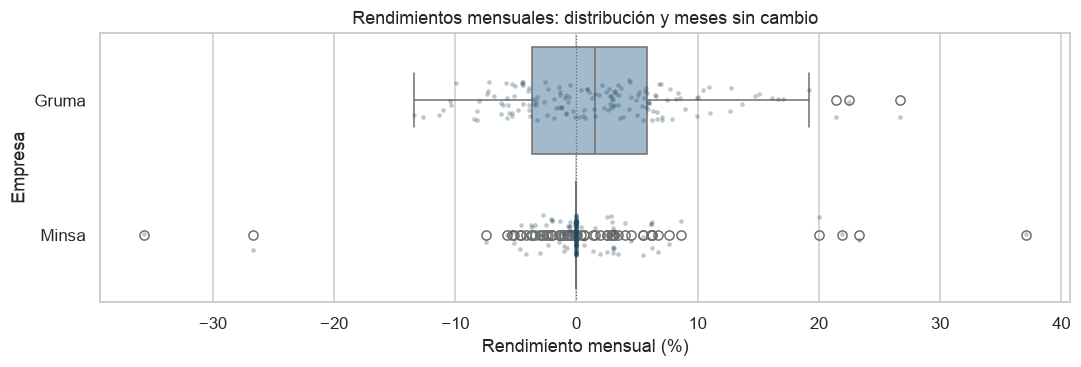

In [7]:
# Resumimos las dos empresas sin repetirlas por mercado.
cobertura_bolsa = bolsa_mensual.groupby("empresa", observed=True).agg(
    meses=("mes", "size"),
    rendimientos_disponibles=("rendimiento_bolsa_pct", "count"),
    meses_sin_cambio=("rendimiento_bolsa_pct", lambda x: x.eq(0).sum()),
    meses_volumen_cero=("volumen", lambda x: x.eq(0).sum()),
    dias_registrados=("dias_registrados", "sum"),
    dias_volumen_cero=("dias_volumen_cero", "sum"),
    rendimiento_minimo_pct=("rendimiento_bolsa_pct", "min"),
    rendimiento_maximo_pct=("rendimiento_bolsa_pct", "max"),
)
cobertura_bolsa["porcentaje_meses_sin_cambio"] = (
    100 * cobertura_bolsa["meses_sin_cambio"] / cobertura_bolsa["rendimientos_disponibles"]
)
display(cobertura_bolsa.round(3))

# Comparamos distribuciones; cada empresa aporta un dato por mes.
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.boxplot(
    data=bolsa_mensual, x="rendimiento_bolsa_pct", y="empresa",
    color="#9bbbd3", ax=ax,
)
sns.stripplot(
    data=bolsa_mensual, x="rendimiento_bolsa_pct", y="empresa",
    color="#21475e", alpha=0.30, jitter=0.15, size=3, ax=ax,
)
ax.axvline(0, color="0.4", linestyle=":", linewidth=0.8)
ax.set(title="Rendimientos mensuales: distribución y meses sin cambio",
       xlabel="Rendimiento mensual (%)", ylabel="Empresa")
fig.tight_layout()
plt.show()


Gruma presenta una mediana ligeramente positiva y mayor dispersión en
la parte central de sus rendimientos.

Minsa concentra muchos meses en 0 %, por eso su caja casi no se distingue.
Sin embargo, registra cambios aislados cercanos a −36 % y +37 %:
combina muchos cierres sin cambio con saltos puntuales pronunciados.

## 5 | Cruce por mes y auditoría

### 5.1 | Unión sin multiplicación accidental de filas

**¿Qué meses de cada mercado pueden compararse con cada empresa?**

La clave común es un periodo mensual; no se intenta unir el día 1 de SNIIM con el fin de mes bursátil. Se une cada empresa por separado con `validate="many_to_one"`, de modo que solo exista un registro financiero por mes. Luego se concatenan las dos comparaciones.

La tabla conserva todos los mercado–mes, incluidos los faltantes. Las correlaciones se calculan por mercado y empresa.


In [8]:
# Unimos por empresa y validamos la cardinalidad de cada cruce.
cruces = []
for ticker in TICKERS:
    financiera = bolsa_mensual.loc[
        bolsa_mensual["ticker"].eq(ticker)
    ].drop(columns="fecha").copy()
    parte = sniim_mensual.merge(
        financiera, on="mes", how="left", validate="many_to_one", indicator=True
    )
    assert parte["_merge"].eq("both").all(), "Hay meses sin fila bursátil."
    cruces.append(parte.drop(columns="_merge"))

cruce = pd.concat(cruces, ignore_index=True)
cruce["par_disponible"] = cruce[
    ["variacion_maiz_pct", "rendimiento_bolsa_pct"]
].notna().all(axis=1)
cruce["periodo"] = pd.Categorical(
    np.select(
        [cruce["mes"].dt.year.le(2019), cruce["mes"].dt.year.le(2022)],
        ["2013–2019", "2020–2022"], default="2023–2025"
    ), categories=PERIODOS, ordered=True,
)
assert not cruce.duplicated(["mercado", "mes", "ticker"]).any()
assert len(cruce) == len(MERCADOS) * len(CALENDARIO) * len(TICKERS)
assert not np.isinf(cruce[
    ["variacion_maiz_pct", "rendimiento_bolsa_pct"]
].to_numpy(dtype=float)).any()
display(cruce[[
    "mes", "mercado", "empresa", "precio_promedio_mxn_kg",
    "numero_precios", "variacion_maiz_pct", "rendimiento_bolsa_pct", "par_disponible"
]].head(10))


,mes,mercado,empresa,precio_promedio_mxn_kg,numero_precios,variacion_maiz_pct,rendimiento_bolsa_pct,par_disponible
0,2013-01,Culiacán,Gruma,4.50,1,NaN,8.399268,False
1,2013-02,Culiacán,Gruma,4.50,1,0.000000,5.958577,True
2,2013-03,Culiacán,Gruma,4.70,1,4.444444,21.382536,True
3,2013-04,Culiacán,Gruma,4.58,1,-2.553191,11.060255,True
4,2013-05,Culiacán,Gruma,4.00,1,-12.663755,-5.638920,True
5,2013-06,Culiacán,Gruma,4.00,1,0.000000,2.778246,True
6,2013-07,Culiacán,Gruma,4.00,1,0.000000,15.028899,True
7,2013-08,Culiacán,Gruma,4.00,1,0.000000,2.143067,True
8,2013-09,Culiacán,Gruma,4.25,2,6.250000,5.657651,True
9,2013-10,Culiacán,Gruma,4.20,1,-1.176471,22.459622,True


In [9]:
# Contamos las observaciones efectivas por pareja.
pares_disponibles = cruce.groupby(["mercado", "empresa"], observed=True).agg(
    meses_calendario=("mes", "size"),
    pares_comparables=("par_disponible", "sum"),
)
pares_disponibles["meses_no_comparables"] = (
    pares_disponibles["meses_calendario"] - pares_disponibles["pares_comparables"]
)
display(pares_disponibles)
print("Meses distintos del estudio:", cruce["mes"].nunique())
print("Pares mercado-mes con Gruma:", int(cruce.loc[
    cruce["empresa"].eq("Gruma"), "par_disponible"
].sum()))


meses_calendario  pares_comparables  meses_no_comparables
mercado     empresa                                                           
Culiacán    Gruma                 156                153                     3
            Minsa                 156                153                     3
Guadalajara Gruma                 156                153                     3
            Minsa                 156                153                     3
Guadalupe   Gruma                 156                152                     4
            Minsa                 156                152                     4
Hermosillo  Gruma                 156                147                     9
            Minsa                 156                147                     9
Iztapalapa  Gruma                 156                151                     5
            Minsa                 156                151                     5

Meses distintos del estudio: 156
Pares mercado-mes con Gruma: 756


### 5.2 | Disponibilidad visual antes de correlacionar

**¿Los huecos de cobertura provienen del maíz o de la bolsa?**

La matriz muestra disponibilidad de variaciones mensuales, no de precios. El primer mes SNIIM y los meses posteriores a un precio ausente pueden aparecer sin variación aunque tengan un precio registrado.


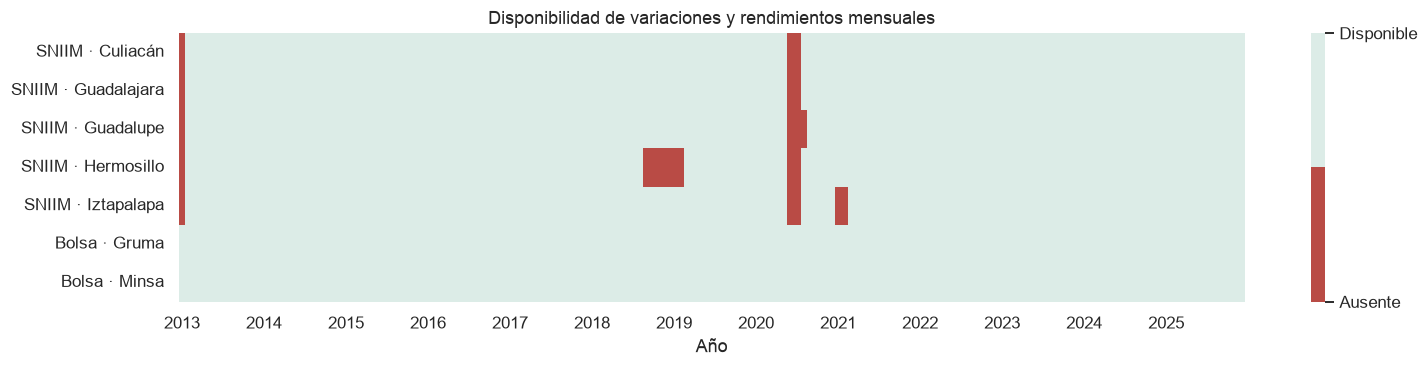

In [10]:
# Construimos una fila por mercado y por empresa.
matriz_maiz = sniim_mensual.pivot(
    index="mercado", columns="mes", values="variacion_maiz_pct"
).reindex(MERCADOS).notna().astype(int)
matriz_maiz.index = "SNIIM · " + matriz_maiz.index
matriz_bolsa = bolsa_mensual.pivot(
    index="empresa", columns="mes", values="rendimiento_bolsa_pct"
).notna().astype(int)
matriz_bolsa.index = "Bolsa · " + matriz_bolsa.index
matriz_cobertura = pd.concat([matriz_maiz, matriz_bolsa]).reindex(columns=CALENDARIO)

# Dibujamos disponibilidad en el calendario completo.
fig, ax = plt.subplots(figsize=(14, 3.5))
sns.heatmap(
    matriz_cobertura, cmap=["#b94b45", "#dcece7"], vmin=0, vmax=1,
    xticklabels=12, yticklabels=True,
    cbar_kws={"ticks": [0, 1]}, ax=ax,
)
ax.set_xticklabels([str(p.year) for p in CALENDARIO[::12]], rotation=0)
ax.tick_params(axis="y", rotation=0)
ax.set(title="Disponibilidad de variaciones y rendimientos mensuales",
       xlabel="Año", ylabel="")
ax.collections[0].colorbar.set_ticklabels(["Ausente", "Disponible"])
fig.tight_layout()
plt.show()


## 6 | Comparación de tasas de cambio mensuales

### 6.1 | Distribución de las tasas de cambio

**¿Con qué frecuencia aparecen cambios pequeños, aumentos o caídas en el maíz y en la acción de Gruma?**

En cada mercado se comparan las distribuciones acumuladas de las dos tasas usando exactamente los meses disponibles para esa pareja. El eje horizontal expresa cambios porcentuales mensuales; el vertical muestra la proporción de meses con una tasa menor o igual a ese valor.

Esta gráfica compara las distribuciones de tasas. La coincidencia entre las dos variables en un mismo mes se examina después mediante series, diagramas de dispersión y correlaciones.


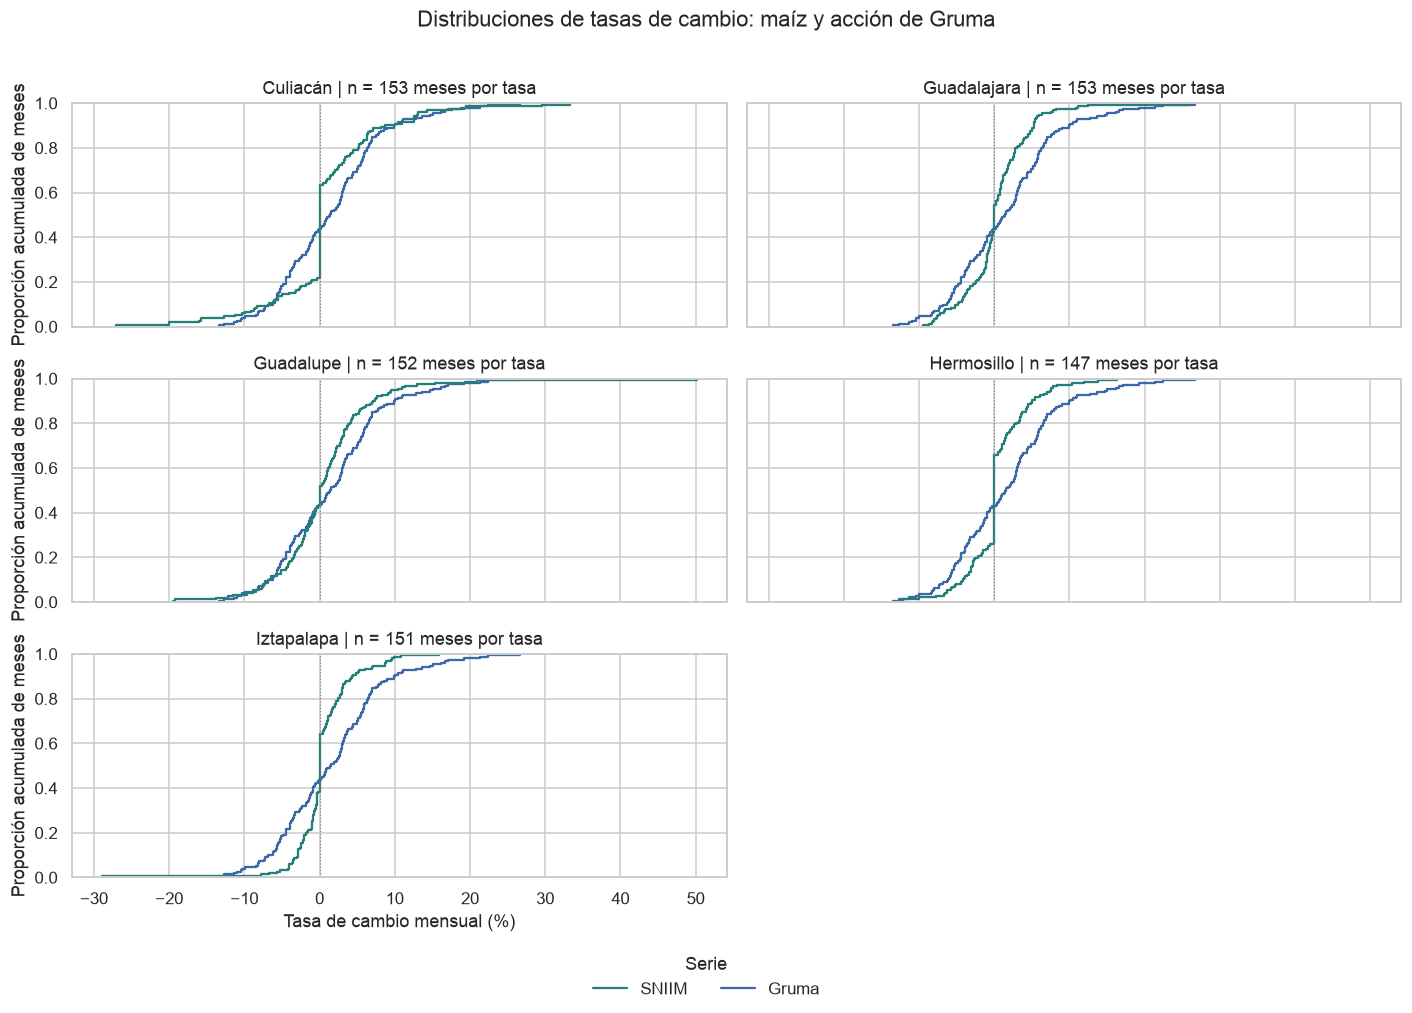

In [11]:
# Seleccionamos los mismos meses comparables en cada pareja.
fig, ejes = plt.subplots(3, 2, figsize=(13, 9), sharex=True, sharey=True)
leyenda_tasas = None
for ax, mercado in zip(ejes.flat, MERCADOS):
    pareja = cruce.loc[
        cruce["mercado"].eq(mercado) & cruce["empresa"].eq("Gruma")
        & cruce["par_disponible"],
        ["mes", "variacion_maiz_pct", "rendimiento_bolsa_pct"],
    ].copy()
    distribucion = pareja.melt(
        id_vars="mes",
        value_vars=["variacion_maiz_pct", "rendimiento_bolsa_pct"],
        var_name="serie", value_name="tasa_mensual_pct",
    )
    distribucion["serie"] = distribucion["serie"].map({
        "variacion_maiz_pct": "SNIIM",
        "rendimiento_bolsa_pct": "Gruma",
    })

    # Dibujamos distribuciones de tasas, sin comparar niveles de precios.
    sns.ecdfplot(
        data=distribucion, x="tasa_mensual_pct", hue="serie",
        palette=COLORES, linewidth=1.5, ax=ax,
    )
    if leyenda_tasas is None:
        leyenda_tasas = (
            list(ax.get_legend().legend_handles),
            [t.get_text() for t in ax.get_legend().get_texts()],
        )
    ax.get_legend().remove()
    ax.axvline(0, color="0.5", linestyle=":", linewidth=0.8)
    ax.set(
        title=f"{mercado} | n = {len(pareja)} meses por tasa",
        xlabel="Tasa de cambio mensual (%)",
        ylabel="Proporción acumulada de meses",
    )
ejes.flat[-1].axis("off")
fig.legend(
    *leyenda_tasas, title="Serie", loc="lower center", ncol=2, frameon=False
)
fig.suptitle("Distribuciones de tasas de cambio: maíz y acción de Gruma", y=1.01)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()


En Guadalajara, Hermosillo e Iztapalapa, las variaciones del maíz están
más concentradas alrededor de cero que los rendimientos de Gruma.

Culiacán y Guadalupe presentan distribuciones más parecidas a la de
Gruma, aunque con algunos cambios del maíz más extremos.

Los saltos de las curvas del maíz en 0 % reflejan la acumulación de
meses en los que el precio promedio permaneció sin cambio.

### 6.2 | Tasas de cambio mensuales comparadas con Gruma

**¿Coinciden los aumentos y disminuciones de la tasa del maíz y la tasa de la acción?**

Ambas tasas se muestran en porcentaje mensual, con escalas compartidas. Cada panel reutiliza la misma tasa bursátil de Gruma para facilitar la comparación con un mercado.

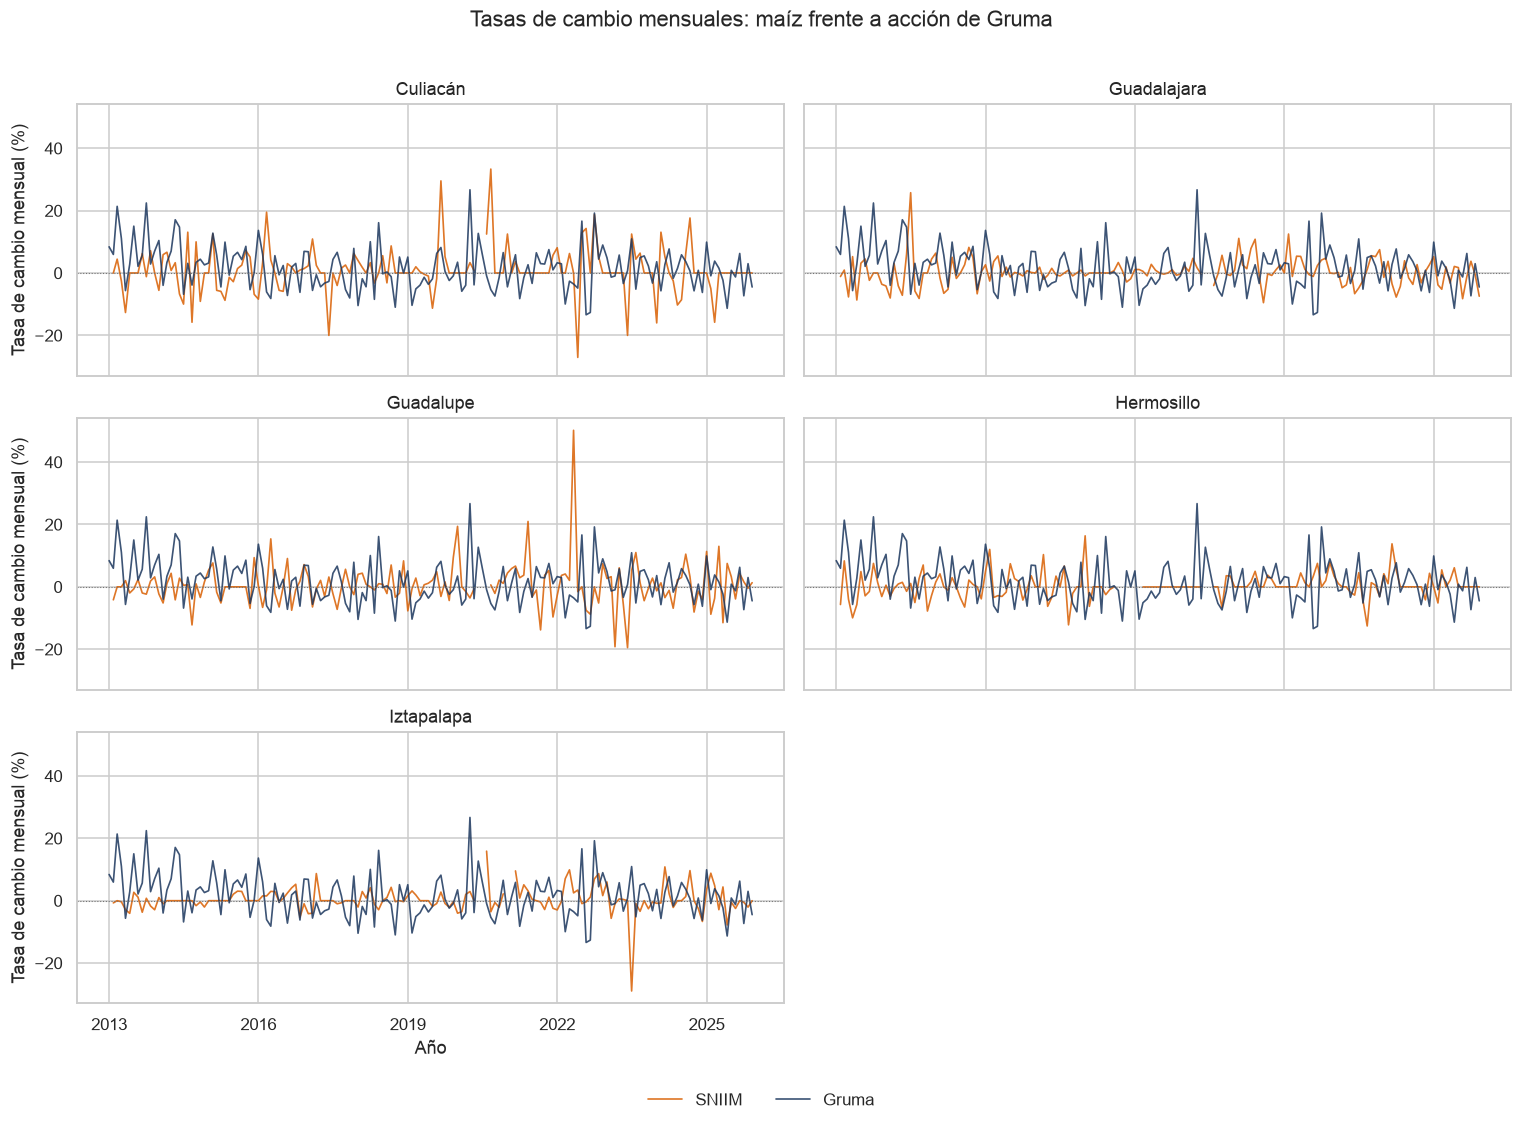

In [12]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns

# Pasamos a formato largo únicamente para dibujar.
paneles = cruce.loc[
    cruce["empresa"].eq("Gruma"),
    ["mercado", "fecha", "variacion_maiz_pct", "rendimiento_bolsa_pct"],
].melt(
    id_vars=["mercado", "fecha"],
    value_vars=["variacion_maiz_pct", "rendimiento_bolsa_pct"],
    var_name="serie",
    value_name="cambio_pct",
)
paneles["serie"] = paneles["serie"].map(
    {"variacion_maiz_pct": "SNIIM", "rendimiento_bolsa_pct": "Gruma"}
)
paneles = paneles.sort_values(["mercado", "serie", "fecha"])
paneles["tramo"] = paneles.groupby(["mercado", "serie"], observed=True)[
    "cambio_pct"
].transform(lambda s: s.isna().cumsum())

# Extraemos la lista de mercados directamente del DataFrame si no está definida
MERCADOS = list(paneles["mercado"].dropna().unique())

# Paleta de alto contraste (cálido vs. frío oscuro)
PALETA_CONTRASTE = {
    "SNIIM": "#D95F02",  # Naranja/ámbar fuerte (maíz)
    "Gruma": "#1B365D",  # Azul marino profundo (acción)
}

# Separamos los tramos para no atravesar huecos.
fig, ejes = plt.subplots(3, 2, figsize=(14, 10), sharex=True, sharey=True)
for ax, mercado in zip(ejes.flat, MERCADOS):
    sns.lineplot(
        data=paneles.loc[paneles["mercado"].eq(mercado)],
        x="fecha",
        y="cambio_pct",
        hue="serie",
        hue_order=["SNIIM", "Gruma"],
        palette=PALETA_CONTRASTE,
        units="tramo",
        estimator=None,
        errorbar=None,
        linewidth=1.1,
        alpha=0.85,
        ax=ax,
    )
    ax.axhline(0, color="0.45", linewidth=0.7, linestyle=":")
    ax.set(title=mercado, xlabel="Año", ylabel="Tasa de cambio mensual (%)")
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    if ax.get_legend() is not None:
        ax.get_legend().remove()

ejes.flat[-1].axis("off")
handles, labels = ejes.flat[0].get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc="lower center",
    ncol=2,
    frameon=False,
)
fig.suptitle("Tasas de cambio mensuales: maíz frente a acción de Gruma", y=1.01)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

Los aumentos y disminuciones del maíz y de Gruma no coinciden de forma
constante. El maíz combina meses de cambios pequeños con saltos puntuales.

Destacan el aumento de Guadalupe en mayo de 2022, cercano al 50 %, y
la caída de Iztapalapa en julio de 2023, cercana al 29 %. Gruma no presenta
movimientos de magnitud similar en esos meses.



### 6.3 | Diagramas de dispersión de las tasas por mercado

**¿La tasa de cambio del precio del maíz se corresponde con una tasa mayor o menor de cambio de la acción de Gruma?**

Cada punto representa las dos tasas del mismo mes comparable. Se conservan todos los valores extremos. 


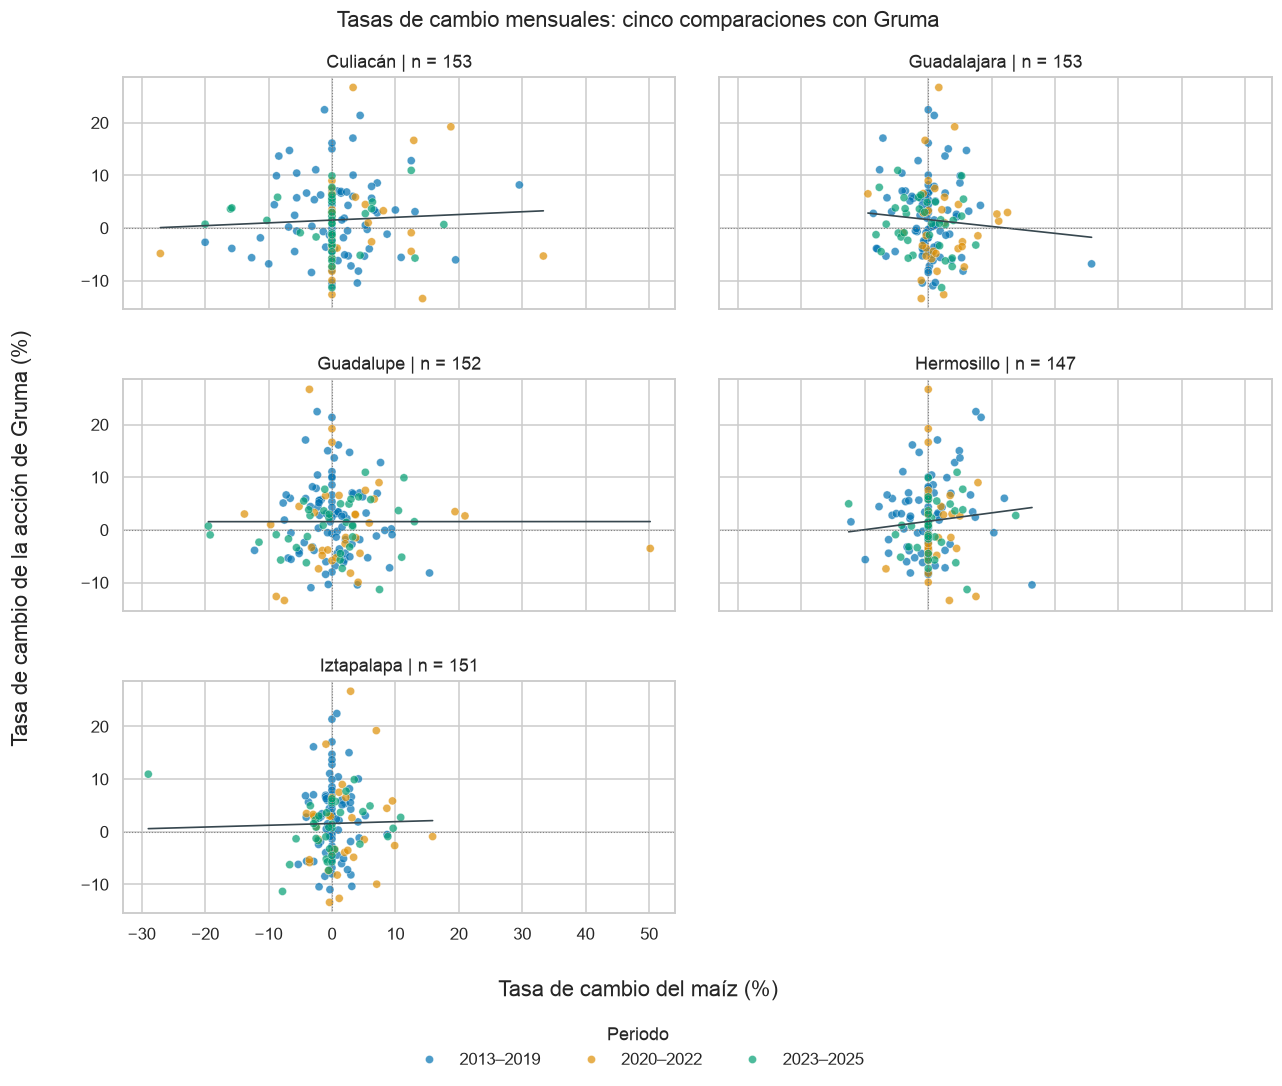

In [13]:
# Dibujamos parejas completas y una recta descriptiva.
fig, ejes = plt.subplots(3, 2, figsize=(12, 10), sharex=True, sharey=True)
leyenda = None
for ax, mercado in zip(ejes.flat, MERCADOS):
    pareja = cruce.loc[
        cruce["empresa"].eq("Gruma") & cruce["mercado"].eq(mercado)
        & cruce["par_disponible"]
    ].copy()
    sns.scatterplot(
        data=pareja, x="variacion_maiz_pct", y="rendimiento_bolsa_pct",
        hue="periodo", hue_order=PERIODOS, palette="colorblind",
        s=28, alpha=0.7, edgecolor="white", linewidth=0.3, ax=ax,
    )
    sns.regplot(
        data=pareja, x="variacion_maiz_pct", y="rendimiento_bolsa_pct",
        scatter=False, ci=None, color="#37474f",
        line_kws={"linewidth": 1.1}, ax=ax,
    )
    if leyenda is None:
        leyenda = ax.get_legend_handles_labels()
    ax.get_legend().remove()
    ax.axhline(0, color="0.5", linestyle=":", linewidth=0.7)
    ax.axvline(0, color="0.5", linestyle=":", linewidth=0.7)
    ax.set(
        title=f"{mercado} | n = {len(pareja)}",
        xlabel="",
        ylabel="",
    )
ejes.flat[-1].axis("off")

fig.supxlabel("Tasa de cambio del maíz (%)", y=0.08)
fig.supylabel("Tasa de cambio de la acción de Gruma (%)", x=0.025)

fig.legend(
    *leyenda,
    title="Periodo",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.005),
    ncol=3,
    frameon=False,
)

fig.suptitle(
    "Tasas de cambio mensuales: cinco comparaciones con Gruma",
    y=0.98,
)

fig.subplots_adjust(
    left=0.11, right=0.98,
    bottom=0.16, top=0.92,
    hspace=0.30, wspace=0.08,
)
plt.show()


Las nubes de puntos presentan bastante dispersión y las rectas tienen pendientes pequeñas. Visualmente, no se aprecia una asociación lineal estrecha entre las variaciones del maíz y los rendimientos de Gruma en el mismo mes.

- En Culiacán, Hermosillo e Iztapalapa se observa una ligera pendiente
  positiva; en Guadalajara es negativa y en Guadalupe casi horizontal.
  Estas inclinaciones son tenues.
- Cuando la variación del maíz está cerca de cero, Gruma presenta tanto
  rendimientos positivos como negativos. Un precio del maíz sin cambio
  registrado no implica que la acción permanezca estable.
- Algunos meses tienen variaciones del maíz alejadas del centro.
  Conviene revisar cuánto influyen en la recta, conservándolos en el
  análisis principal.
- Los colores de los tres periodos se superponen en la zona central;
  esta vista no muestra grupos claramente separados por periodo.


## 7 | Correlaciones contemporáneas

### 7.1 | Pearson, Spearman y tamaño de cada pareja

**¿Cuál es la dirección y magnitud de la asociación en el mismo mes?**


In [14]:
# Calculamos ambos coeficientes con una regla común para datos constantes.
def resumir_pareja(tabla):
    pareja = tabla[["variacion_maiz_pct", "rendimiento_bolsa_pct"]].dropna()
    resultado = {"n": len(pareja), "pearson": np.nan, "spearman": np.nan}
    if len(pareja) >= 3 and pareja.nunique().ge(2).all():
        resultado["pearson"] = pareja.corr(method="pearson").iloc[0, 1]
        resultado["spearman"] = pareja.corr(method="spearman").iloc[0, 1]
    return resultado

filas = []
for (mercado, empresa), grupo in cruce.groupby(["mercado", "empresa"], observed=True):
    filas.append({"mercado": mercado, "empresa": empresa, **resumir_pareja(grupo)})
correlaciones = pd.DataFrame(filas)
display(correlaciones.set_index(["empresa", "mercado"]).round(3))


,,n,pearson,spearman
empresa,mercado,,,
Gruma,Culiacán,153,0.057,0.029
Minsa,Culiacán,153,0.111,-0.017
Gruma,Guadalajara,153,-0.081,-0.101
Minsa,Guadalajara,153,-0.178,-0.046
Gruma,Guadalupe,152,0.000,0.028
Minsa,Guadalupe,152,-0.174,-0.058
Gruma,Hermosillo,147,0.093,0.135
Minsa,Hermosillo,147,-0.067,-0.013
Gruma,Iztapalapa,151,0.020,0.104


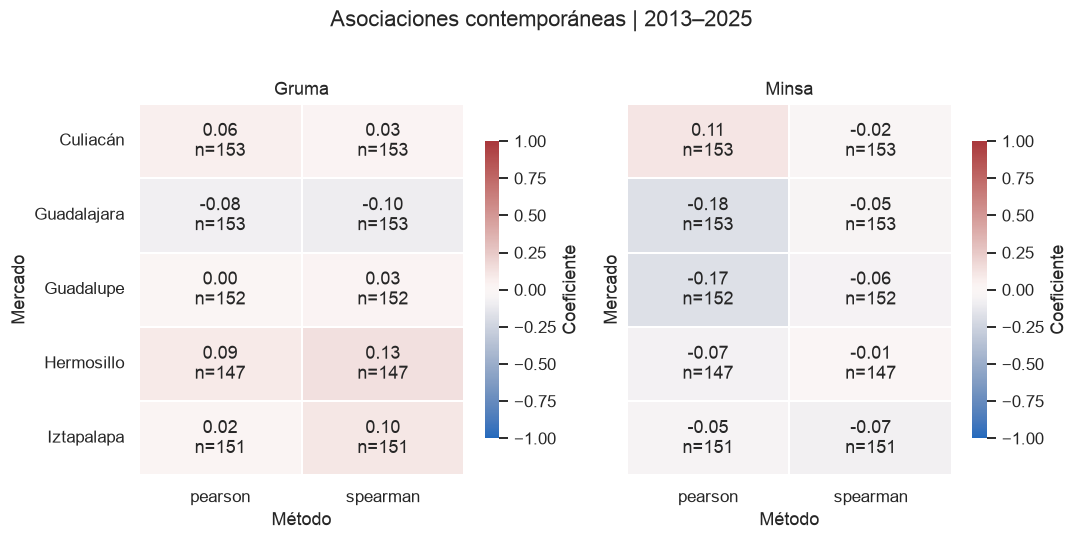

In [15]:
# Mostramos magnitud y número de meses en la misma figura.
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.8), sharey=True)
for ax, empresa in zip(ejes, ["Gruma", "Minsa"]):
    tabla = correlaciones.loc[correlaciones["empresa"].eq(empresa)].set_index("mercado").reindex(MERCADOS)
    valores = tabla[["pearson", "spearman"]]
    anotaciones = valores.map(lambda x: f"{x:.2f}").copy()
    for mercado in MERCADOS:
        for metodo in valores.columns:
            anotaciones.loc[mercado, metodo] += f"\nn={int(tabla.loc[mercado, 'n'])}"
    sns.heatmap(
        valores, annot=anotaciones, fmt="", cmap="vlag", center=0,
        vmin=-1, vmax=1, linewidths=1, linecolor="white",
        cbar_kws={"label": "Coeficiente", "shrink": 0.8}, ax=ax,
    )
    ax.set(title=empresa, xlabel="Método", ylabel="Mercado")
    ax.tick_params(axis="y", rotation=0)
fig.suptitle("Asociaciones contemporáneas | 2013–2025", y=1.02)
fig.tight_layout()
fig.savefig(raiz / "reports" / "figures" / "cruce_sniim_bolsa_correlaciones.png", dpi=150, bbox_inches="tight")
plt.show()


### 7.2 | Lectura del resultado principal

Gruma presenta Pearson entre **−0.081 y 0.093** y Spearman entre **−0.101 y 0.135**. Son asociaciones contemporáneas de magnitud reducida. No aparece una correspondencia lineal o monotónica estrecha entre los cambios mensuales del maíz de estos mercados y el rendimiento de la acción.


## 8 | Anomalías y sensibilidad del cruce

### 8.1 | Señalar candidatos sin eliminarlos

**¿Qué cambios extremos podrían influir en las correlaciones?**

Se aplican dos criterios exploratorios sobre las variaciones: IQR con límites Q1 − 1.5×IQR y Q3 + 1.5×IQR, y |z| > 3 con desviación muestral. Cada mercado y cada empresa se evalúan en su propia distribución, sin duplicar sus registros por el cruce.


In [16]:
# Marcamos candidatos en una copia y documentamos criterios degenerados.
def marcar_extremos(tabla, columna, agrupador):
    copia = tabla.copy(deep=True)
    limites = []
    copia["candidato_iqr"] = False
    copia["candidato_z"] = False
    for etiqueta, indices_grupo in copia.groupby(agrupador, observed=True).groups.items():
        serie = copia.loc[indices_grupo, columna]
        q1, q3 = serie.quantile([0.25, 0.75])
        iqr = q3 - q1
        media, desviacion = serie.mean(), serie.std(ddof=1)
        iqr_evaluable = bool(pd.notna(iqr) and iqr > 0)
        z_evaluable = bool(pd.notna(desviacion) and desviacion > 0)
        if iqr_evaluable:
            copia.loc[indices_grupo, "candidato_iqr"] = (
                serie.lt(q1 - 1.5 * iqr) | serie.gt(q3 + 1.5 * iqr)
            )
        if z_evaluable:
            copia.loc[indices_grupo, "candidato_z"] = (
                ((serie - media) / desviacion).abs().gt(3)
            )
        limites.append({
            "grupo": etiqueta, "n": serie.notna().sum(), "iqr": iqr,
            "iqr_evaluable": iqr_evaluable, "z_evaluable": z_evaluable,
            "candidatos_iqr": int(copia.loc[indices_grupo, "candidato_iqr"].sum()),
            "candidatos_z": int(copia.loc[indices_grupo, "candidato_z"].sum()),
        })
    return copia, pd.DataFrame(limites)

maiz_marcado, revision_extremos_maiz = marcar_extremos(
    sniim_mensual, "variacion_maiz_pct", "mercado"
)
bolsa_marcada, revision_extremos_bolsa = marcar_extremos(
    bolsa_mensual, "rendimiento_bolsa_pct", "empresa"
)
display(revision_extremos_maiz.round(3))
display(revision_extremos_bolsa.round(3))


,grupo,n,iqr,iqr_evaluable,z_evaluable,candidatos_iqr,candidatos_z
0,Culiacán,153,3.333,True,True,37,3
1,Guadalajara,153,3.731,True,True,14,1
2,Guadalupe,152,5.769,True,True,10,1
3,Hermosillo,147,2.363,True,True,27,4
4,Iztapalapa,151,2.537,True,True,16,2


,grupo,n,iqr,iqr_evaluable,z_evaluable,candidatos_iqr,candidatos_z
0,Gruma,156,9.518,True,True,3,1
1,Minsa,156,0.000,False,True,0,6


### 8.2 | Tres escenarios adicionales para Gruma

**¿Cambia la descripción al revisar composición por origen y cambios extremos?**


n  pearson  spearman
mercado     escenario                                 
Culiacán    Principal           153    0.057     0.029
            Mismos orígenes     143    0.090     0.051
            Sin candidatos IQR  113    0.082     0.074
            Sin candidatos z    149    0.039     0.006
Guadalajara Principal           153   -0.081    -0.101
            Mismos orígenes     147   -0.060    -0.100
            Sin candidatos IQR  136   -0.044    -0.105
            Sin candidatos z    151   -0.052    -0.096
Guadalupe   Principal           152    0.000     0.028
            Mismos orígenes     132    0.032     0.079
            Sin candidatos IQR  139    0.087     0.060
            Sin candidatos z    150    0.059     0.050
Hermosillo  Principal           147    0.093     0.135
            Mismos orígenes     144    0.092     0.134
            Sin candidatos IQR  119    0.104     0.111
            Sin candidatos z    142    0.187     0.174
Iztapalapa  Principal           151    0.020     0.104
            Mismos orígenes     147    0.018     0.091
            Sin candidatos IQR  132    0.030     0.057
            Sin candidatos z    148    0.107     0.118

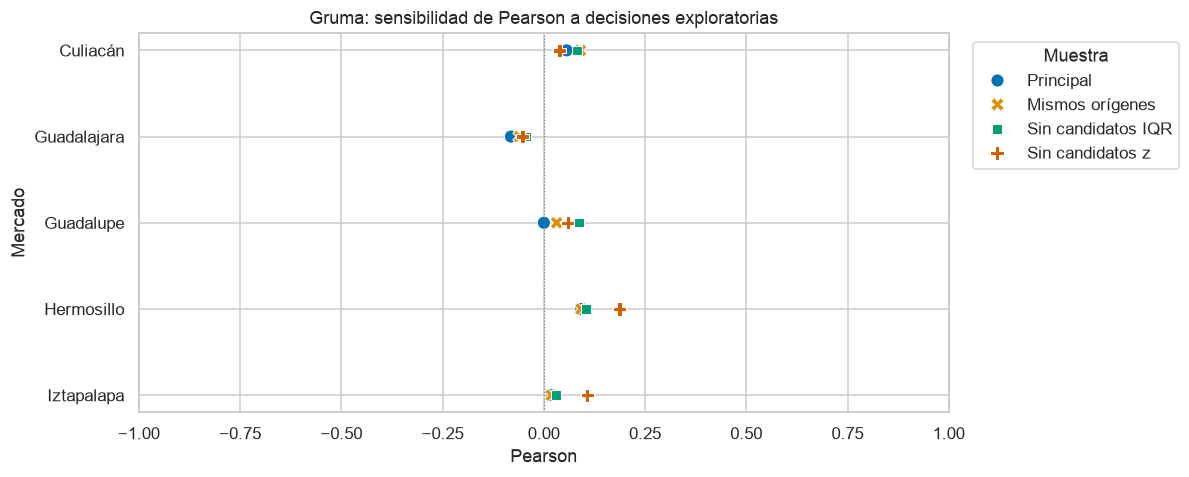

In [17]:
# Añadimos banderas al cruce sin alterar la tabla principal.
banderas_maiz = maiz_marcado[["mercado", "mes", "candidato_iqr", "candidato_z"]].rename(
    columns={"candidato_iqr": "maiz_iqr", "candidato_z": "maiz_z"}
)
banderas_bolsa = bolsa_marcada[["ticker", "mes", "candidato_iqr", "candidato_z"]].rename(
    columns={"candidato_iqr": "bolsa_iqr", "candidato_z": "bolsa_z"}
)
cruce_revision = (
    cruce.merge(banderas_maiz, on=["mercado", "mes"], validate="many_to_one")
    .merge(banderas_bolsa, on=["ticker", "mes"], validate="many_to_one")
)
sensibilidad_filas = []
for mercado, grupo in cruce_revision.loc[
    cruce_revision["empresa"].eq("Gruma")
].groupby("mercado", observed=True):
    escenarios = {
        "Principal": grupo,
        "Mismos orígenes": grupo.loc[grupo["mismos_origenes"]],
        "Sin candidatos IQR": grupo.loc[~(grupo["maiz_iqr"] | grupo["bolsa_iqr"])],
        "Sin candidatos z": grupo.loc[~(grupo["maiz_z"] | grupo["bolsa_z"])],
    }
    for escenario, seleccion in escenarios.items():
        sensibilidad_filas.append({
            "mercado": mercado, "escenario": escenario, **resumir_pareja(seleccion)
        })
sensibilidad = pd.DataFrame(sensibilidad_filas)
display(sensibilidad.set_index(["mercado", "escenario"]).round(3))

# Contrastamos las magnitudes sin ocultar los cambios de muestra.
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.scatterplot(
    data=sensibilidad, x="pearson", y="mercado", hue="escenario",
    style="escenario", hue_order=[
        "Principal", "Mismos orígenes", "Sin candidatos IQR", "Sin candidatos z"
    ], palette="colorblind", s=75, ax=ax,
)
ax.axvline(0, color="0.5", linewidth=0.8, linestyle=":")
ax.set(xlim=(-1, 1), title="Gruma: sensibilidad de Pearson a decisiones exploratorias",
       xlabel="Pearson", ylabel="Mercado")
ax.legend(title="Muestra", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()


Las correlaciones siguen siendo débiles al mantener los mismos orígenes
o excluir valores extremos. El mayor cambio aparece en Hermosillo:
Pearson pasa de 0.093 a 0.187 al excluir los candidatos por z-score.

Los filtros también reducen los meses comparados: en Culiacán,
por ejemplo, quedan 113 de 153 meses al aplicar IQR.

### 8.3 | Inspección del mayor aumento del maíz

**¿Cómo se comportó la bolsa en el mes del salto revisado de Guadalupe?**

El caso se selecciona por el cambio del maíz ya documentado en la libreta 01, no por maximizar una correlación. 

In [18]:
# Inspeccionamos abril, mayo y junio de 2022.
caso = cruce.loc[
    cruce["mercado"].eq("Guadalupe") & cruce["empresa"].eq("Gruma")
    & cruce["mes"].between(pd.Period("2022-04", "M"), pd.Period("2022-06", "M")),
    ["mes", "numero_precios", "origenes",
     "variacion_maiz_pct", "rendimiento_bolsa_pct"],
].copy()
# Redondeamos solo columnas numéricas, conservando el periodo mensual.
caso_mostrar = caso.copy()
columnas_numericas = caso_mostrar.select_dtypes(include="number").columns
caso_mostrar[columnas_numericas] = caso_mostrar[columnas_numericas].round(3)
display(caso_mostrar)


,mes,numero_precios,origenes,variacion_maiz_pct,rendimiento_bolsa_pct
423,2022-04,1,"(Tamaulipas,)",2.075,-2.615
424,2022-05,1,"(Tamaulipas,)",50.185,-3.519
425,2022-06,1,"(Tamaulipas,)",-1.538,-4.836


### 8.4 | Sensibilidad a la selección del origen principal

**¿Cambian las correlaciones si usamos una serie priorizada por cobertura?**

Para cada mercado se ordenan los orígenes por cantidad global de precios presentes en 2013–2025; los empates se resuelven por nombre. Se selecciona la fila de mayor prioridad entre las filas que existen en cada mes. Si esa fila existe pero no tiene precio, permanece ausente aunque otro origen tenga precio.


In [19]:
# Ordenamos orígenes por cobertura dentro de cada mercado.
prioridades = (
    sniim.groupby(["mercado", "origen"], observed=True)["precio_mxn_kg"]
    .count().rename("precios_observados").reset_index()
    .sort_values(["mercado", "precios_observados", "origen"],
                 ascending=[True, False, True])
)
prioridades["prioridad"] = prioridades.groupby("mercado", observed=True).cumcount() + 1

# Seleccionamos una fila por mercado y mes sin sustituir precios ausentes.
seleccion_origen = (
    sniim.merge(prioridades[["mercado", "origen", "prioridad"]],
                on=["mercado", "origen"], validate="many_to_one")
    .sort_values(["mercado", "mes", "prioridad"])
    .drop_duplicates(["mercado", "mes"])
    .set_index(["mercado", "mes"])
    .reindex(indice_esperado).reset_index()
)
seleccion_origen["tasa_origen_pct"] = (
    seleccion_origen.groupby("mercado", observed=True)["precio_mxn_kg"]
    .pct_change(fill_method=None).mul(100)
)

# Contrastamos ambas definiciones con la misma serie de Gruma.
comparacion_origen = []
for mercado in MERCADOS:
    principal = cruce.loc[
        cruce["mercado"].eq(mercado) & cruce["empresa"].eq("Gruma")
    ]
    alternativa = seleccion_origen.loc[
        seleccion_origen["mercado"].eq(mercado),
        ["mes", "tasa_origen_pct"],
    ].merge(
        bolsa_mensual.loc[bolsa_mensual["empresa"].eq("Gruma"),
                          ["mes", "rendimiento_bolsa_pct"]],
        on="mes", validate="one_to_one",
    ).rename(columns={"tasa_origen_pct": "variacion_maiz_pct"})
    # Igualamos los meses para distinguir cobertura de definición.
    meses_alternativa = alternativa.loc[
        alternativa[["variacion_maiz_pct", "rendimiento_bolsa_pct"]].notna().all(axis=1),
        "mes",
    ]
    principal_comun = principal.loc[principal["mes"].isin(meses_alternativa)]
    for metodo, tabla in [("Media de orígenes", principal),
                          ("Media, mismos meses que origen", principal_comun),
                          ("Origen priorizado", alternativa)]:
        comparacion_origen.append({
            "mercado": mercado, "definicion": metodo, **resumir_pareja(tabla)
        })
comparacion_origen = pd.DataFrame(comparacion_origen)
display(prioridades)
display(comparacion_origen.set_index(["mercado", "definicion"]).round(3))


,mercado,origen,precios_observados,prioridad
1,Culiacán,Sinaloa,135,1
0,Culiacán,Jalisco,25,2
3,Guadalajara,Jalisco,143,1
2,Guadalajara,Importación,15,2
7,Guadalupe,Tamaulipas,141,1
5,Guadalupe,Sinaloa,20,2
4,Guadalupe,Coahuila,3,3
6,Guadalupe,Tabasco,2,4
10,Hermosillo,Sonora,78,1
9,Hermosillo,Sinaloa,68,2


n  pearson  spearman
mercado     definicion                                            
Culiacán    Media de orígenes               153    0.057     0.029
            Media, mismos meses que origen  130    0.072     0.046
            Origen priorizado               130    0.067     0.026
Guadalajara Media de orígenes               153   -0.081    -0.101
            Media, mismos meses que origen  140   -0.062    -0.081
            Origen priorizado               140   -0.054    -0.072
Guadalupe   Media de orígenes               152    0.000     0.028
            Media, mismos meses que origen  133    0.009     0.049
            Origen priorizado               133    0.010     0.061
Hermosillo  Media de orígenes               147    0.093     0.135
            Media, mismos meses que origen  142    0.093     0.136
            Origen priorizado               142    0.093     0.136
Iztapalapa  Media de orígenes               151    0.020     0.104
            Media, mismos meses que origen  137    0.023     0.109
            Origen priorizado               137    0.020     0.105

## 9 | Comparación temporal y análisis de Minsa

### 9.1 | Tres periodos de calendario

**¿El coeficiente de toda la ventana oculta diferencias entre periodos?**

Se comparan tres periodos: **2013–2019**, **2020–2022** y **2023–2025**.


n  pearson  spearman
mercado     periodo                         
Culiacán    2013–2019  83    0.058     0.018
            2020–2022  34    0.126     0.135
            2023–2025  36   -0.047    -0.034
Guadalajara 2013–2019  83   -0.103    -0.088
            2020–2022  34   -0.003     0.032
            2023–2025  36   -0.133    -0.149
Guadalupe   2013–2019  83   -0.084    -0.081
            2020–2022  33    0.006     0.146
            2023–2025  36    0.187     0.270
Hermosillo  2013–2019  77    0.169     0.192
            2020–2022  34   -0.030     0.031
            2023–2025  36    0.060     0.151
Iztapalapa  2013–2019  83    0.028     0.041
            2020–2022  32    0.094     0.101
            2023–2025  36   -0.052     0.250

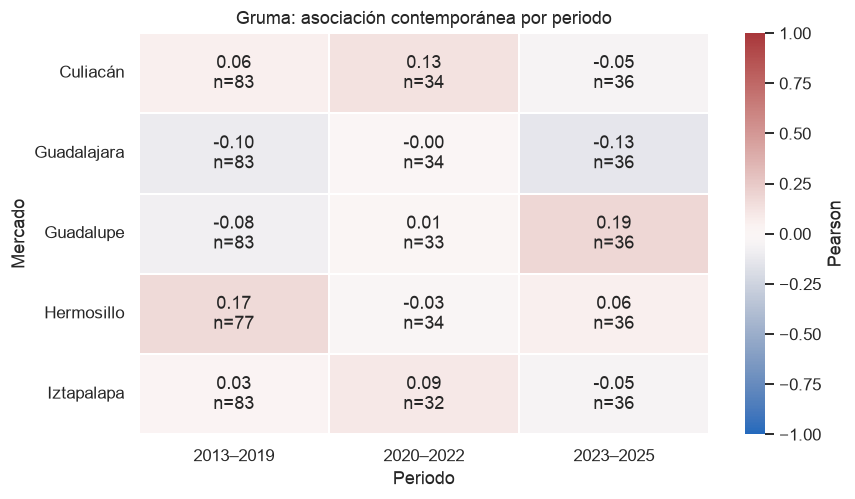

In [20]:
# Repetimos la misma definición por mercado y periodo.
filas_periodos = []
for (mercado, periodo), grupo in cruce.loc[
    cruce["empresa"].eq("Gruma")
].groupby(["mercado", "periodo"], observed=True):
    filas_periodos.append({"mercado": mercado, "periodo": periodo, **resumir_pareja(grupo)})
correlaciones_periodos = pd.DataFrame(filas_periodos)
display(correlaciones_periodos.set_index(["mercado", "periodo"]).round(3))

# Conservamos la escala completa para no exagerar asociaciones pequeñas.
valores = correlaciones_periodos.pivot(
    index="mercado", columns="periodo", values="pearson"
).reindex(index=MERCADOS, columns=PERIODOS)
conteos = correlaciones_periodos.pivot(
    index="mercado", columns="periodo", values="n"
).reindex(index=MERCADOS, columns=PERIODOS)
anotaciones = valores.map(lambda x: f"{x:.2f}")
for mercado in valores.index:
    for periodo in valores.columns:
        anotaciones.loc[mercado, periodo] += f"\nn={int(conteos.loc[mercado, periodo])}"
fig, ax = plt.subplots(figsize=(8, 4.7))
sns.heatmap(
    valores, annot=anotaciones, fmt="", cmap="vlag", vmin=-1, vmax=1,
    center=0, linewidths=1, cbar_kws={"label": "Pearson"}, ax=ax,
)
ax.set(title="Gruma: asociación contemporánea por periodo", xlabel="Periodo", ylabel="Mercado")
ax.tick_params(axis="both", rotation=0)
fig.tight_layout()
plt.show()


Las correlaciones son débiles en los tres periodos. Guadalupe presenta
el valor más alto en 2023–2025 (0.19), mientras que Hermosillo destaca
en 2013–2019 (0.17).

Guadalajara mantiene valores negativos o cercanos a cero. En los demás
mercados cambia el signo entre periodos, sin una dirección constante.

### 9.2 | Sensibilidad de la comparación secundaria

**¿Cómo cambia la descripción al considerar solo los meses con movimiento de Minsa?**

Se compara la serie completa de Minsa con los meses en que su rendimiento es distinto de cero.


In [21]:
# Comparamos Minsa completa con sus meses de rendimiento distinto de cero.
filas_minsa = []
for mercado, grupo in cruce.loc[
    cruce["empresa"].eq("Minsa")
].groupby("mercado", observed=True):
    for etiqueta, seleccion in [
        ("Todos los pares", grupo),
        ("Minsa con movimiento", grupo.loc[grupo["rendimiento_bolsa_pct"].ne(0)]),
    ]:
        filas_minsa.append({"mercado": mercado, "muestra": etiqueta,
                            **resumir_pareja(seleccion)})
sensibilidad_minsa = pd.DataFrame(filas_minsa)
display(sensibilidad_minsa.set_index(["mercado", "muestra"]).round(3))


n  pearson  spearman
mercado     muestra                                     
Culiacán    Todos los pares       153    0.111    -0.017
            Minsa con movimiento   69    0.120     0.014
Guadalajara Todos los pares       153   -0.178    -0.046
            Minsa con movimiento   69   -0.286    -0.112
Guadalupe   Todos los pares       152   -0.174    -0.058
            Minsa con movimiento   68   -0.217    -0.116
Hermosillo  Todos los pares       147   -0.067    -0.013
            Minsa con movimiento   67   -0.096    -0.127
Iztapalapa  Todos los pares       151   -0.048    -0.072
            Minsa con movimiento   68   -0.095    -0.026

### 9.3 | Comparación de ventanas de eventos

**¿Cuánto depende la lectura de un evento de dónde comienza la ventana?**

Se usan dos fechas de trabajo: COVID-19 (11 marzo 2020) e invasión de Ucrania (24 febrero 2022).

Se comparan dos convenciones claramente separadas:

1. **Incluye el mes del evento:** desde el cierre del mes previo hasta el cierre de dos meses después; son tres cambios mensuales que incluyen el mes del evento.
2. **Convención de fechas:** desde el cierre del propio mes del evento hasta el cierre de tres meses después. Omite la variación del mes del evento.

Las variaciones se calculan por mercado y con precios disponibles en todos los meses de la ventana.


In [22]:
# Definimos fechas y convenciones antes de calcular ventanas.
eventos_revision = pd.DataFrame([
    ("2020-03-11", "COVID-19"),
    ("2022-02-24", "Invasión de Ucrania"),
], columns=["fecha", "evento"])
eventos_revision["fecha"] = pd.to_datetime(eventos_revision["fecha"])
convenciones = {
    "Incluye mes del evento [-1,+2]": (-1, 2),
    "Convención: desde cierre del evento [0,+3]": (0, 3),
}
precios_por_mercado = sniim_mensual.pivot(
    index="mes", columns="mercado", values="precio_promedio_mxn_kg"
)
cierres_gruma = copias_bolsa["GRUMAB.MX"].set_index("mes")["cierre_ajustado"]

# Conservamos ausencias y mostramos la base real de cada comparación.
filas_eventos = []
for _, evento in eventos_revision.iterrows():
    mes_evento = evento["fecha"].to_period("M")
    for convencion, (antes, despues) in convenciones.items():
        base, final = mes_evento + antes, mes_evento + despues
        meses_ventana = pd.period_range(base, final, freq="M")
        bolsa_ventana = cierres_gruma.reindex(meses_ventana)
        tasa_accion = (
            100 * (bolsa_ventana.iloc[-1] / bolsa_ventana.iloc[0] - 1)
            if bolsa_ventana.notna().all() else np.nan
        )
        for mercado in MERCADOS:
            valores = precios_por_mercado[mercado].reindex(meses_ventana)
            completa = valores.notna().all()
            tasa_maiz = 100 * (valores.iloc[-1] / valores.iloc[0] - 1) if completa else np.nan
            filas_eventos.append({
                "evento": evento["evento"], "mercado": mercado,
                "convencion": convencion, "mes_base": str(base),
                "mes_final": str(final), "meses_sniim_ausentes": int(valores.isna().sum()),
                "tasa_maiz_ventana_pct": tasa_maiz,
                "tasa_accion_ventana_pct": tasa_accion,
            })
revision_eventos = pd.DataFrame(filas_eventos)
display(revision_eventos.round({
    "tasa_maiz_ventana_pct": 2, "tasa_accion_ventana_pct": 2
}))


,evento,mercado,convencion,mes_base,mes_final,meses_sniim_ausentes,tasa_maiz_ventana_pct,tasa_accion_ventana_pct
0,COVID-19,Culiacán,"Incluye mes del evento [-1,+2]",2020-02,2020-05,0,4.17,17.11
1,COVID-19,Guadalajara,"Incluye mes del evento [-1,+2]",2020-02,2020-05,0,6.11,17.11
2,COVID-19,Guadalupe,"Incluye mes del evento [-1,+2]",2020-02,2020-05,0,-5.63,17.11
3,COVID-19,Hermosillo,"Incluye mes del evento [-1,+2]",2020-02,2020-05,0,0.00,17.11
4,COVID-19,Iztapalapa,"Incluye mes del evento [-1,+2]",2020-02,2020-05,0,5.00,17.11
5,COVID-19,Culiacán,"Convención: desde cierre del evento [0,+3]",2020-03,2020-06,1,NaN,37.36
6,COVID-19,Guadalajara,"Convención: desde cierre del evento [0,+3]",2020-03,2020-06,1,NaN,37.36
7,COVID-19,Guadalupe,"Convención: desde cierre del evento [0,+3]",2020-03,2020-06,1,NaN,37.36
8,COVID-19,Hermosillo,"Convención: desde cierre del evento [0,+3]",2020-03,2020-06,1,NaN,37.36
9,COVID-19,Iztapalapa,"Convención: desde cierre del evento [0,+3]",2020-03,2020-06,1,NaN,37.36


## 10 | Cruce anual SNIIM–DGSIAP y contexto bursátil

### 10.1 | Archivos disponibles y unidad de observación

**¿Qué cobertura tienen los archivos DGSIAP disponibles?**

Se leen los CSV anuales de DGSIAP. Se filtra **Maíz grano**; esta categoría no permite aislar maíz blanco. Se conservan todos los estados disponibles, incluidos los orígenes fuera de los cinco estados de mercado, como Tamaulipas.

Una fila cruda se identifica por año, estado, DDR, CADER, municipio, ciclo, modalidad, cultivo y unidad. Se comprueban duplicados y cantidades negativas antes de agregar. `Precio` y `Rendimiento` de los registros no se promedian automáticamente: se reconstruyen las medidas agregadas a partir de totales.


In [23]:
# Leemos únicamente archivos anuales y registramos sus huellas.
rutas_dgsiap = sorted(
    p for p in (raiz / "data" / "raw" / "DGSIAP").glob("*.csv")
    if p.stem.isdigit() and 2013 <= int(p.stem) <= 2025
)
if not rutas_dgsiap:
    raise FileNotFoundError("No hay CSV anuales DGSIAP en data/raw/DGSIAP.")
huellas_dgsiap_iniciales = {
    str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in rutas_dgsiap
}
tablas_dgsiap = []
auditoria_archivos = []
columnas_cantidad = ["Sembrada", "Cosechada", "Siniestrada",
                     "Volumenproduccion", "Valorproduccion"]
clave_dgsiap = ["Anio", "Idestado", "Idddr", "Idcader", "Idmunicipio",
                "Idciclo", "Idmodalidad", "Idcultivo", "Idunidadmedida"]

# Homologamos nombres en copias y auditamos cada año.
for archivo in rutas_dgsiap:
    tabla = pd.read_csv(archivo, low_memory=False).copy(deep=True)
    if "Nomcultivo" not in tabla:
        tabla = tabla.rename(columns={"Nomcultivo Sin Um": "Nomcultivo"})
    elif "Nomcultivo Sin Um" in tabla:
        tabla["Nomcultivo"] = tabla["Nomcultivo"].fillna(tabla["Nomcultivo Sin Um"])
    tabla = tabla.loc[tabla["Nomcultivo"].str.strip().eq("Maíz grano")].copy()
    tabla = tabla.drop(columns=[c for c in tabla if str(c).startswith("Unnamed:")])
    for columna in columnas_cantidad:
        tabla[columna] = pd.to_numeric(
            tabla[columna].astype(str).str.replace(",", "", regex=False),
            errors="coerce",
        )
    assert not tabla.duplicated(clave_dgsiap).any(), archivo.name
    assert tabla[columnas_cantidad].notna().all().all(), archivo.name
    assert tabla[columnas_cantidad].ge(0).all().all(), archivo.name
    assert tabla["Nomunidad"].str.strip().eq("Tonelada").all(), archivo.name
    assert tabla["Anio"].eq(int(archivo.stem)).all(), archivo.name
    auditoria_archivos.append({
        "archivo": archivo.name, "registros_maiz": len(tabla),
        "estados": tabla["Idestado"].nunique(),
        "sin_produccion": int(tabla["Volumenproduccion"].eq(0).sum()),
        "produccion_sin_valor": int(
            (tabla["Volumenproduccion"].gt(0) & tabla["Valorproduccion"].eq(0)).sum()
        ),
    })
    tablas_dgsiap.append(tabla)

dgsiap_copia = pd.concat(tablas_dgsiap, ignore_index=True)
anios_dgsiap = sorted(dgsiap_copia["Anio"].unique())
anios_dgsiap_faltantes = sorted(set(range(2013, 2026)) - set(anios_dgsiap))
display(pd.DataFrame(auditoria_archivos))
print("Años presentes:", anios_dgsiap)
print("Años no disponibles aquí:", anios_dgsiap_faltantes)


,archivo,registros_maiz,estados,sin_produccion,produccion_sin_valor
0,2018.csv,4591,32,9,0
1,2019.csv,4639,32,52,0
2,2020.csv,4608,32,21,0
3,2021.csv,4591,32,1,0
4,2022.csv,4620,32,11,0
5,2023.csv,4669,32,54,0
6,2024.csv,4589,32,19,0
7,2025.csv,4558,32,10,0


Años presentes: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Años no disponibles aquí: [2013, 2014, 2015, 2016, 2017]


### 10.2 | Totales, precio ponderado y rendimiento agrícola

**¿Cómo resumimos municipios, ciclos y modalidades sin dar el mismo peso a unidades de tamaños distintos?**

- Superficie: suma de hectáreas.
- Producción: suma de toneladas.
- Valor: suma de pesos corrientes.
- Rendimiento agrícola estatal: toneladas totales / hectáreas cosechadas.
- Precio rural ponderado: valor monetario / volumen de las partidas con producción y valor positivos; después se divide entre 1,000 para MXN/kg.

Se reporta la proporción del volumen con valor positivo.


In [24]:
# Agregamos cantidades físicas y monetarias por estado y año.
produccion_estado = dgsiap_copia.groupby(
    ["Idestado", "Anio"], observed=True
).agg(
    estado_produccion=("Nomestado", "first"),
    superficie_sembrada_ha=("Sembrada", "sum"),
    superficie_cosechada_ha=("Cosechada", "sum"),
    superficie_siniestrada_ha=("Siniestrada", "sum"),
    produccion_t=("Volumenproduccion", "sum"),
    valor_produccion_mxn=("Valorproduccion", "sum"),
    registros=("Idcultivo", "size"),
)

# Calculamos precio sobre las partidas con producción y valor positivos.
partidas_valorizadas = dgsiap_copia.loc[
    dgsiap_copia["Volumenproduccion"].gt(0)
    & dgsiap_copia["Valorproduccion"].gt(0)
]
valoracion = partidas_valorizadas.groupby(["Idestado", "Anio"], observed=True).agg(
    volumen_valorizado_t=("Volumenproduccion", "sum"),
    valor_valorizado_mxn=("Valorproduccion", "sum"),
)
produccion_estado = produccion_estado.join(valoracion)
produccion_estado["precio_rural_mxn_kg"] = (
    produccion_estado["valor_valorizado_mxn"]
    / produccion_estado["volumen_valorizado_t"] / 1000
)
produccion_estado["cobertura_valorizacion_pct"] = (
    100 * produccion_estado["volumen_valorizado_t"]
    / produccion_estado["produccion_t"].replace(0, np.nan)
)
produccion_estado["rendimiento_agricola_t_ha"] = (
    produccion_estado["produccion_t"]
    / produccion_estado["superficie_cosechada_ha"].replace(0, np.nan)
)
produccion_estado = produccion_estado.reset_index().rename(columns={"Anio": "anio"})

# Reindexamos años para no saltar huecos al calcular tasas anuales.
calendario_estatal = pd.MultiIndex.from_product(
    [sorted(produccion_estado["Idestado"].unique()), range(2013, 2026)],
    names=["Idestado", "anio"],
)
produccion_estado = (
    produccion_estado.set_index(["Idestado", "anio"])
    .reindex(calendario_estatal).reset_index()
)
for columna, tasa in [
    ("produccion_t", "tasa_produccion_anual_pct"),
    ("precio_rural_mxn_kg", "tasa_precio_rural_anual_pct"),
]:
    produccion_estado[tasa] = (
        produccion_estado.groupby("Idestado", observed=True)[columna]
        .pct_change(fill_method=None).mul(100)
    )
assert not produccion_estado.duplicated(["Idestado", "anio"]).any()
display(produccion_estado.loc[
    produccion_estado["Idestado"].isin([9, 14, 19, 25, 26, 28])
    & produccion_estado["produccion_t"].notna(),
    ["Idestado", "estado_produccion", "anio", "produccion_t",
     "precio_rural_mxn_kg", "rendimiento_agricola_t_ha", "cobertura_valorizacion_pct"]
].round(3))


,Idestado,estado_produccion,anio,produccion_t,precio_rural_mxn_kg,rendimiento_agricola_t_ha,cobertura_valorizacion_pct
109,9,Ciudad de México,2018,4834.45,4.887,1.352,100.0
110,9,Ciudad de México,2019,3990.42,5.205,1.172,100.0
111,9,Ciudad de México,2020,4495.92,5.180,1.317,100.0
112,9,Ciudad de México,2021,4200.13,5.259,1.232,100.0
113,9,Ciudad de México,2022,4954.90,5.562,1.431,100.0
114,9,Ciudad de México,2023,4379.98,6.420,1.359,100.0
115,9,Ciudad de México,2024,4055.76,7.285,1.281,100.0
116,9,Ciudad de México,2025,4874.14,7.572,1.493,100.0
174,14,Jalisco,2018,3847214.27,3.916,6.622,100.0
175,14,Jalisco,2019,3818364.89,4.357,6.475,100.0


### 10.3 | Cobertura y tasas anuales de SNIIM y Gruma

**¿Cómo mantenemos años comparables sin rellenar meses?**

La media anual SNIIM se calcula a partir de los precios mensuales por mercado, no directamente sobre todas las filas por origen. Se conservan sus meses observados y se exige un mínimo operativo de 10. Los años que no cumplen permanecen ausentes para las tasas; se muestra su cobertura.

El rendimiento anual de Gruma compara el cierre ajustado de diciembre con diciembre anterior. No se usa la media de los rendimientos mensuales. En esta copia están los cierres necesarios, incluido diciembre de 2012.


,mercado,anio,meses_con_precio,cumple_cobertura
44,Hermosillo,2018,8,False


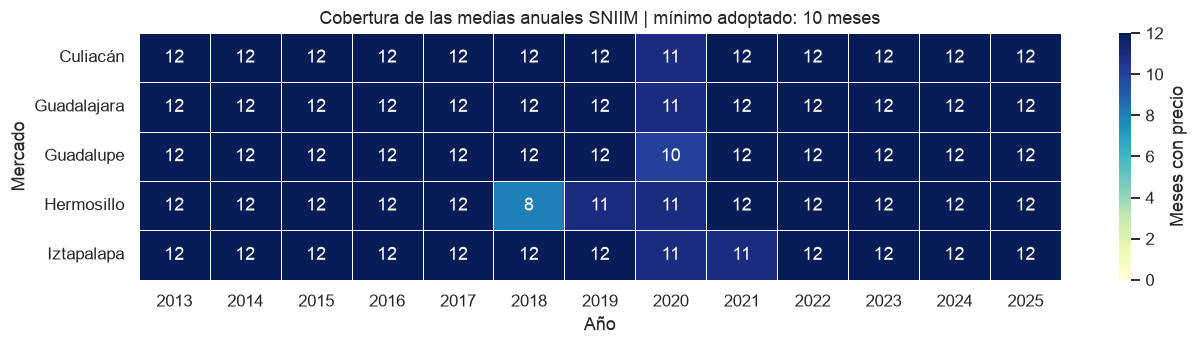

In [25]:
MIN_MESES_ANUALES = 10

# Resumimos precios mensuales con un calendario anual completo.
sniim_anual_referencia = (
    sniim_mensual.assign(anio=lambda d: d["mes"].dt.year)
    .groupby(["mercado", "anio"], observed=True)
    .agg(
        precio_sniim_anual_observado=("precio_promedio_mxn_kg", "mean"),
        meses_con_precio=("precio_promedio_mxn_kg", "count"),
    ).reset_index().sort_values(["mercado", "anio"])
)
sniim_anual_referencia["cumple_cobertura"] = (
    sniim_anual_referencia["meses_con_precio"].ge(MIN_MESES_ANUALES)
)
sniim_anual_referencia["precio_sniim_anual_comparable"] = (
    sniim_anual_referencia["precio_sniim_anual_observado"]
    .where(sniim_anual_referencia["cumple_cobertura"])
)
sniim_anual_referencia["tasa_sniim_anual_pct"] = (
    sniim_anual_referencia.groupby("mercado", observed=True)[
        "precio_sniim_anual_comparable"
    ].pct_change(fill_method=None).mul(100)
)

# Vinculamos cada mercado con su estado de venta de forma explícita.
ids_estado = {
    "Ciudad de México": 9, "Jalisco": 14, "Nuevo León": 19,
    "Sinaloa": 25, "Sonora": 26, "Tamaulipas": 28,
    "México": 15, "Coahuila": 5, "Tabasco": 27,
}
ubicaciones = sniim[["mercado", "estado_mercado"]].drop_duplicates()
assert ubicaciones["mercado"].is_unique
sniim_anual_referencia = sniim_anual_referencia.merge(
    ubicaciones, on="mercado", validate="many_to_one"
)
sniim_anual_referencia["Idestado"] = (
    sniim_anual_referencia["estado_mercado"].map(ids_estado).astype("Int64")
)

# Calculamos tasas anuales bursátiles a partir de cierres de diciembre.
base_gruma = copias_bolsa["GRUMAB.MX"].copy()
diciembre = base_gruma.loc[base_gruma["mes"].dt.month.eq(12)].copy()
diciembre["anio"] = diciembre["mes"].dt.year
cierres_anuales = diciembre.set_index("anio")["cierre_ajustado"].reindex(range(2012, 2026))
gruma_anual = (
    cierres_anuales.pct_change(fill_method=None).mul(100)
    .rename("tasa_accion_anual_pct").rename_axis("anio").reset_index()
)
display(sniim_anual_referencia.loc[
    ~sniim_anual_referencia["cumple_cobertura"],
    ["mercado", "anio", "meses_con_precio", "cumple_cobertura"]
])

# Dibujamos cobertura; los números no son precios ni producción.
cobertura_anual = sniim_anual_referencia.pivot(
    index="mercado", columns="anio", values="meses_con_precio"
).reindex(MERCADOS)
fig, ax = plt.subplots(figsize=(12, 3.3))
sns.heatmap(
    cobertura_anual, annot=True, fmt=".0f", cmap="YlGnBu",
    vmin=0, vmax=12, linewidths=0.6,
    cbar_kws={"label": "Meses con precio"}, ax=ax,
)
ax.set(title="Cobertura de las medias anuales SNIIM | mínimo adoptado: 10 meses",
       xlabel="Año", ylabel="Mercado")
ax.tick_params(axis="both", rotation=0)
fig.tight_layout()
plt.show()


### 10.4 | Cruce por estado del mercado: contexto territorial

**¿Cómo se comparan las tasas de la producción estatal, el precio rural y el precio mayorista del mercado de venta?**

Se une por código estatal y año y se incorpora el rendimiento anual de Gruma. La producción corresponde al estado donde se ubica el mercado; el cruce por origen se presenta en el apartado siguiente.


,mercado,estado_mercado,anio,meses_con_precio,tasa_sniim_anual_pct,tasa_precio_rural_anual_pct,tasa_produccion_anual_pct,tasa_accion_anual_pct,cuatro_tasas_disponibles
5,Culiacán,Sinaloa,2018,12,7.940,NaN,NaN,-9.040,False
6,Culiacán,Sinaloa,2019,12,11.574,-5.301,10.693,-10.346,True
7,Culiacán,Sinaloa,2020,11,9.091,1.331,-2.202,24.262,True
8,Culiacán,Sinaloa,2021,12,22.174,60.649,-12.111,12.735,True
9,Culiacán,Sinaloa,2022,12,18.832,13.557,-4.089,2.568,True
10,Culiacán,Sinaloa,2023,12,16.750,-15.647,25.374,21.698,True
11,Culiacán,Sinaloa,2024,12,-3.007,-19.677,-49.392,6.225,True
12,Culiacán,Sinaloa,2025,12,-11.869,26.999,-32.459,-4.007,True
18,Guadalajara,Jalisco,2018,12,0.234,NaN,NaN,-9.040,False
19,Guadalajara,Jalisco,2019,12,3.332,11.271,-0.750,-10.346,True


,anios_dgsiap,anios_con_cuatro_tasas
mercado,,
Culiacán,8,7
Guadalajara,8,7
Guadalupe,8,7
Hermosillo,8,6
Iztapalapa,8,7


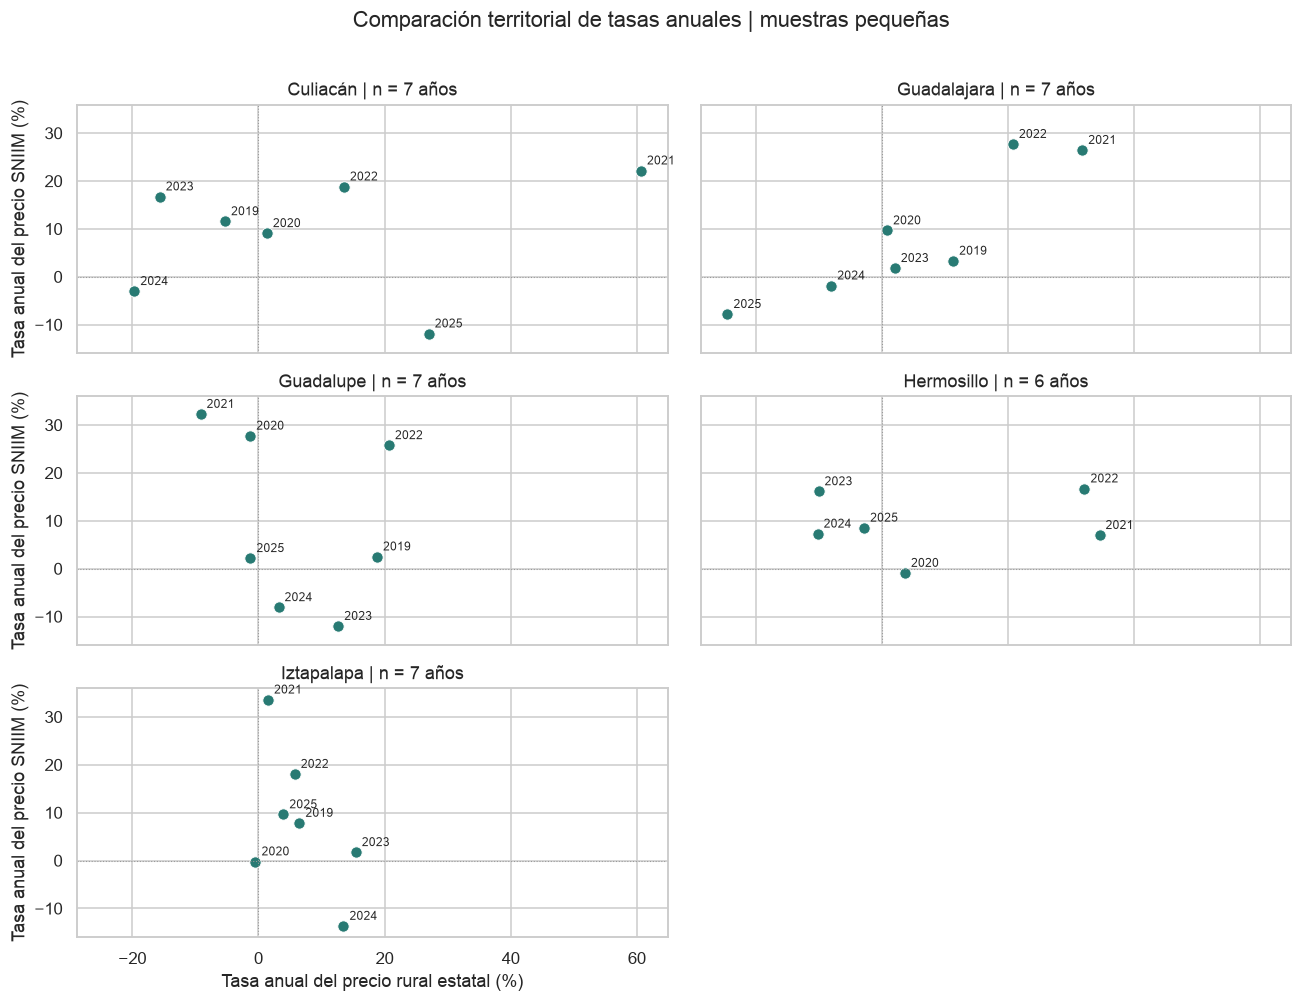

In [26]:
# Unimos sin convertir la falta de un año DGSIAP en producción cero.
cruce_anual_territorial = sniim_anual_referencia.merge(
    produccion_estado, on=["Idestado", "anio"], how="left",
    validate="one_to_one", indicator="union_estatal",
).merge(gruma_anual, on="anio", how="left", validate="many_to_one")
cruce_anual_territorial["dgsiap_observado"] = (
    cruce_anual_territorial["produccion_t"].notna()
)
columnas_tasas_anuales = [
    "tasa_sniim_anual_pct", "tasa_precio_rural_anual_pct",
    "tasa_produccion_anual_pct", "tasa_accion_anual_pct",
]
cruce_anual_territorial["cuatro_tasas_disponibles"] = (
    cruce_anual_territorial[columnas_tasas_anuales].notna().all(axis=1)
)
display(cruce_anual_territorial.loc[
    cruce_anual_territorial["dgsiap_observado"],
    ["mercado", "estado_mercado", "anio", "meses_con_precio",
     *columnas_tasas_anuales, "cuatro_tasas_disponibles"]
].round(3))

# Reportamos tamaños por mercado antes de interpretar los cruces.
cobertura_cruce_anual = cruce_anual_territorial.groupby("mercado", observed=True).agg(
    anios_dgsiap=("dgsiap_observado", "sum"),
    anios_con_cuatro_tasas=("cuatro_tasas_disponibles", "sum"),
)
display(cobertura_cruce_anual)

# Visualizamos tasas anuales, conservando el reducido tamaño de cada pareja.
fig, ejes = plt.subplots(3, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, mercado in zip(ejes.flat, MERCADOS):
    pareja = cruce_anual_territorial.loc[
        cruce_anual_territorial["mercado"].eq(mercado)
    ].dropna(subset=["tasa_sniim_anual_pct", "tasa_precio_rural_anual_pct"])
    sns.scatterplot(
        data=pareja, x="tasa_precio_rural_anual_pct", y="tasa_sniim_anual_pct",
        color="#287a73", s=55, ax=ax,
    )
    for _, fila in pareja.iterrows():
        ax.annotate(
            str(int(fila["anio"])),
            (fila["tasa_precio_rural_anual_pct"], fila["tasa_sniim_anual_pct"]),
            xytext=(4, 4), textcoords="offset points", fontsize=8,
        )
    ax.axhline(0, color="0.6", linestyle=":", linewidth=0.7)
    ax.axvline(0, color="0.6", linestyle=":", linewidth=0.7)
    ax.set(title=f"{mercado} | n = {len(pareja)} años",
           xlabel="Tasa anual del precio rural estatal (%)",
           ylabel="Tasa anual del precio SNIIM (%)")
ejes.flat[-1].axis("off")
fig.suptitle("Comparación territorial de tasas anuales | muestras pequeñas", y=1.01)
fig.tight_layout()
plt.show()


Las variaciones del precio rural estatal y del precio mayorista SNIIM
muestran comportamientos distintos entre mercados.

En Guadalajara, ambos precios registran sus mayores aumentos en 2021
y 2022. En cambio, durante 2023 el precio rural disminuye en Sinaloa
y Sonora, mientras el mayorista aumenta en Culiacán y Hermosillo.

Guadalupe presenta el caso contrario en 2023: aumenta el precio rural
de Nuevo León y disminuye el precio mayorista del mercado.

### 10.5 | Cruce alternativo por origen del grano

**¿Qué cambia al usar el estado de origen, en lugar del estado donde se vende?**

Se conserva una serie anual por **mercado–origen** y se une con la producción de ese origen. Se aplica el mismo umbral de 10 meses y un calendario anual completo antes de calcular tasas.

Se incluyen todos los estados disponibles en DGSIAP, entre ellos Tamaulipas. La categoría Importación queda sin correspondencia estatal.


In [27]:
# Creamos años completos para cada pareja mercado–origen.
origen_anual = (
    sniim.assign(anio=lambda d: d["mes"].dt.year)
    .groupby(["mercado", "origen", "anio"], observed=True)
    .agg(
        precio_origen_anual_observado=("precio_mxn_kg", "mean"),
        meses_origen_observados=("precio_mxn_kg", "count"),
    )
)
parejas_origen = sniim[["mercado", "origen"]].drop_duplicates()
indice_origen_anual = pd.MultiIndex.from_tuples(
    [(fila.mercado, fila.origen, anio)
     for fila in parejas_origen.itertuples(index=False)
     for anio in range(2013, 2026)],
    names=["mercado", "origen", "anio"],
)
origen_anual = origen_anual.reindex(indice_origen_anual).reset_index()
origen_anual["meses_origen_observados"] = (
    origen_anual["meses_origen_observados"].fillna(0).astype(int)
)
origen_anual["precio_origen_comparable"] = (
    origen_anual["precio_origen_anual_observado"].where(
        origen_anual["meses_origen_observados"].ge(MIN_MESES_ANUALES)
    )
)
origen_anual["tasa_origen_anual_pct"] = (
    origen_anual.groupby(["mercado", "origen"], observed=True)[
        "precio_origen_comparable"
    ].pct_change(fill_method=None).mul(100)
)
origen_anual["Idestado"] = origen_anual["origen"].map(ids_estado).astype("Int64")
cruce_anual_origen = origen_anual.merge(
    produccion_estado, on=["Idestado", "anio"], how="left", validate="many_to_one"
)
cruce_anual_origen["par_tasas_origen_disponible"] = (
    cruce_anual_origen[["tasa_origen_anual_pct", "tasa_precio_rural_anual_pct"]]
    .notna().all(axis=1)
)
display(cruce_anual_origen.groupby(["mercado", "origen"], observed=True).agg(
    anios_con_precio_suficiente=("precio_origen_comparable", "count"),
    anios_con_dgsiap=("produccion_t", "count"),
    pares_de_tasas_anuales=("par_tasas_origen_disponible", "sum"),
))
print("Importación permanece sin correspondencia territorial DGSIAP.")


anios_con_precio_suficiente  anios_con_dgsiap  pares_de_tasas_anuales
mercado     origen                                                                            
Culiacán    Jalisco                                1                 8                       0
            Sinaloa                                9                 8                       7
Guadalajara Importación                            0                 0                       0
            Jalisco                               11                 8                       5
Guadalupe   Coahuila                               0                 8                       0
            Sinaloa                                1                 8                       0
            Tabasco                                0                 8                       0
            Tamaulipas                            11                 8                       6
Hermosillo  Jalisco                                0                 8                       0
            Sinaloa                                5                 8                       0
            Sonora                                 6                 8                       5
Iztapalapa  México                                 0                 8                       0
            Sinaloa                               11                 8                       7

Importación permanece sin correspondencia territorial DGSIAP.


### 10.6 | Cobertura del cruce anual

Los seis años disponibles permiten calcular hasta **cinco cambios anuales de DGSIAP** por estado. La cobertura de SNIIM puede reducir las parejas comparables.


## 11 | Síntesis de resultados

### 11.1 | Resumen cuantitativo del cruce

El siguiente resumen se actualiza con los resultados de la ejecución.


In [28]:
# Resumimos los resultados del cruce.
gruma_resultados = correlaciones.loc[correlaciones["empresa"].eq("Gruma")].copy()
display(gruma_resultados[["mercado", "n", "pearson", "spearman"]].set_index("mercado").round(3))

n_principal = int(gruma_resultados["n"].sum())
n_sin_precio = int(sniim_mensual["precio_promedio_mxn_kg"].isna().sum())
cero_minsa = int(cobertura_bolsa.loc["Minsa", "meses_sin_cambio"])
alternativos = sensibilidad.loc[sensibilidad["escenario"].ne("Principal")]
peor_cambio = (
    sensibilidad.merge(
        gruma_resultados[["mercado", "pearson"]].rename(columns={"pearson": "pearson_principal"}),
        on="mercado", validate="many_to_one"
    ).assign(cambio=lambda d: (d["pearson"] - d["pearson_principal"]).abs())
)
mayor_cambio = peor_cambio.loc[peor_cambio["cambio"].idxmax()]
max_temporal = correlaciones_periodos.loc[correlaciones_periodos["pearson"].abs().idxmax()]

display(Markdown(
    f"1. **Cobertura:** {len(CALENDARIO)} meses por empresa y cinco mercados; "
    f"{n_sin_precio} combinaciones mercado–mes sin precio y **{n_principal} pares "
    f"mercado–mes evaluables frente a Gruma**.\n\n"
    f"2. **Resultado principal:** Pearson entre **{gruma_resultados['pearson'].min():.3f} y "
    f"{gruma_resultados['pearson'].max():.3f}**; Spearman entre "
    f"**{gruma_resultados['spearman'].min():.3f} y {gruma_resultados['spearman'].max():.3f}**. "
    "La asociación es débil en los cinco mercados.\n\n"
    f"3. **Sensibilidad:** en las muestras alternativas de Gruma, el mayor |Pearson| es "
    f"**{alternativos['pearson'].abs().max():.3f}**. El mayor cambio respecto al principal es "
    f"{mayor_cambio['cambio']:.3f}, en {mayor_cambio['mercado']} "
    f"({mayor_cambio['escenario']}, n={int(mayor_cambio['n'])}). "
    "\n\n"
    f"4. **Periodos:** la mayor magnitud de Pearson de las ventanas mostradas aparece en "
    f"{max_temporal['mercado']}, {max_temporal['periodo']}: "
    f"**{max_temporal['pearson']:.3f}**, con n={int(max_temporal['n'])}. "
    "\n\n"
    f"5. **Minsa:** tiene **{cero_minsa} de 156 meses sin cambio de cierre ajustado**. "
    "Se mantiene como comparación secundaria."
))

# Comprobamos que no se modificó el CSV de entrada.
huella_sniim_final = hashlib.sha256(ruta_sniim.read_bytes()).hexdigest()
assert huella_sniim_final == huella_sniim_inicial
assert sniim_original.equals(pd.read_csv(ruta_sniim, parse_dates=["fecha"]))
print("CSV SNIIM intacto.")

# Contrastamos las reglas de origen y la cobertura anual incorporada.
comparacion_gruma_origen = comparacion_origen.loc[
    comparacion_origen["definicion"].eq("Origen priorizado")
]
n_anual_tasas = int(cruce_anual_territorial["cuatro_tasas_disponibles"].sum())
display(Markdown(
    f"6. **Regla de origen:** la serie priorizada aporta entre "
    f"{int(comparacion_gruma_origen['n'].min())} y "
    f"{int(comparacion_gruma_origen['n'].max())} meses por mercado. "
    f"Su mayor |Pearson| con Gruma es "
    f"{comparacion_gruma_origen['pearson'].abs().max():.3f}. "
    "\n\n"
    f"7. **DGSIAP local:** {len(anios_dgsiap)} años disponibles "
    f"({min(anios_dgsiap)}–{max(anios_dgsiap)}), con "
    f"{n_anual_tasas} combinaciones mercado–año que tienen las cuatro tasas. "
    "\n\n"
    "8. **Eventos:** se comparan dos ventanas de tres cambios mensuales, "
    "con distinto mes de inicio."
))
assert all(
    hashlib.sha256(Path(ruta).read_bytes()).hexdigest() == huella
    for ruta, huella in huellas_dgsiap_iniciales.items()
)
print("CSV DGSIAP intactos.")


,n,pearson,spearman
mercado,,,
Culiacán,153,0.057,0.029
Guadalajara,153,-0.081,-0.101
Guadalupe,152,0.000,0.028
Hermosillo,147,0.093,0.135
Iztapalapa,151,0.020,0.104


1. **Cobertura:** 156 meses por empresa y cinco mercados; 12 combinaciones mercado–mes sin precio y **756 pares mercado–mes evaluables frente a Gruma**.

2. **Resultado principal:** Pearson entre **-0.081 y 0.093**; Spearman entre **-0.101 y 0.135**. La asociación es débil en los cinco mercados.

3. **Sensibilidad:** en las muestras alternativas de Gruma, el mayor |Pearson| es **0.187**. El mayor cambio respecto al principal es 0.095, en Hermosillo (Sin candidatos z, n=142). 

4. **Periodos:** la mayor magnitud de Pearson de las ventanas mostradas aparece en Guadalupe, 2023–2025: **0.187**, con n=36. 

5. **Minsa:** tiene **86 de 156 meses sin cambio de cierre ajustado**. Se mantiene como comparación secundaria.

CSV SNIIM intacto.


6. **Regla de origen:** la serie priorizada aporta entre 130 y 142 meses por mercado. Su mayor |Pearson| con Gruma es 0.093. 

7. **DGSIAP local:** 8 años disponibles (2018–2025), con 34 combinaciones mercado–año que tienen las cuatro tasas. 

8. **Eventos:** se comparan dos ventanas de tres cambios mensuales, con distinto mes de inicio.

CSV DGSIAP intactos.
